<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №18: Быстрые samplers и distillation компактной diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Переиспользовать checkpoint lab 17.
- Сравнить DDPM, DDIM и дополнительный solver.
- Обучить compact student и построить Pareto frontier.

## Теоретическая часть

DDIM использует тот же denoiser, но может идти по сокращённой последовательности timesteps детерминированно. Distillation обучает student воспроизводить несколько teacher steps одним шагом. Сравнение строится при одинаковых initial noise и labels.


DDIM вычисляет x̂0 и делает детерминированный переход между точками ᾱ. DPM-Solver++ использует тот же обученный ε-предсказатель. Progressive distillation аппроксимирует двумя teacher-переходами один student-переход; teacher заморожен.

Детерминированный DDIM-переход: $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\hat\epsilon)/\sqrt{\bar\alpha_t}$, $x_s=\sqrt{\bar\alpha_s}\hat x_0+\sqrt{1-\bar\alpha_s}\hat\epsilon$. При конечном $s=-1$ полагаем $\bar\alpha_{-1}=1$.

### Экспериментальный протокол

Обязательная зависимость — реально обученные веса ddpm.pt, classifier.pt и classifier_validation.json из lab 17. Используйте те же классы, noise и guidance=3 при сравнении. Smoke не является подтверждением качества distillation. Для длинных запусков обеспечьте постоянный каталог artifacts (Drive).

### Материалы

- [DDIM](https://arxiv.org/abs/2010.02502)
- [Progressive Distillation](https://arxiv.org/abs/2202.00512)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

Генератор картинок из случайного шума, но быстрее, без потерь качества

**Ускорение**:
- способ 1: умные сэмплеры - У нас та же обученная модель (учитель). Но мы пропускаем большинство шагов: вместо 1000 делаем 10–50.
- способ 2 - distillation (требует обучения): обучаем вторую модель (студента), которая делает 2 шага учителя за 1 свой. Пары «вход → выход»: подаём учителю что-то, он делает 2 шага, получаем эталон. Учим студента делать то же за 1 шаг.


## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [ ]:
from pathlib import Path
import os, json, random, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
from torchvision.utils import save_image, make_grid
import matplotlib.pyplot as plt
from collections import Counter

SEED = 42
FAST_DEV_RUN = False   # True для smoke. Для сдачи поставьте False и перезапустите ядро.

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', 'data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    dest = ARTIFACTS / name
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_text(json.dumps(value, ensure_ascii=False, indent=2))

def save_fig(name, fig=None, dpi=120):
    if fig is None: fig = plt.gcf()
    (ARTIFACTS / name).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(ARTIFACTS / name, dpi=dpi, bbox_inches='tight')
    plt.show(); plt.close(fig)

def to_imshow(t):
    t = t.detach().cpu()
    if t.dim() == 4: t = t[0]
    if t.dim() == 3:
        if t.shape[0] == 1: return t[0].numpy()
        return t.permute(1, 2, 0).numpy()
    return t.numpy()

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN,
       'artifacts': str(ARTIFACTS.resolve()),
       'data_root': str(DATA_ROOT.resolve())})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/artifacts', 'data_root': '/content/data'}


### Проверка обученного teacher

*Вес: 1 балл.*

**Постановка.** Сравнение sampler допустимо лишь при одинаковой обученной модели, классах и исходном шуме. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите checkpoint lab 17, запретите случайную замену и проверьте совместимость шагов/T.

**Результат.** Проверяемое состояние «Проверка обученного teacher» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите checkpoint lab 17, запретите случайную замену и проверьте совместимость шагов/T» и его результат доступен следующему этапу.

In [ ]:
# === Восстановление Lab 17: только если ddpm_checkpoint.pt утерян ===
# Использует те же seed, данные, архитектуру, гиперпараметры.
# На Colab T4: ~20-30 мин. На CPU: ~2-3 ч.
from pathlib import Path
import os, json, random, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms

SEED = 42
FAST_RESTORE = False   # True = 1 эпоха (смоук, НЕ для Lab 18!)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
DATA_ROOT = Path('data'); DATA_ROOT.mkdir(exist_ok=True)

# --- Архитектуры (идентичны Lab 17) ---
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, time):
        half = self.dim // 2
        e = torch.log(torch.tensor(10000.0, device=time.device)) / (half - 1)
        e = torch.exp(torch.arange(half, device=time.device) * -e)
        e = time[:, None] * e[None, :]
        return torch.cat((e.sin(), e.cos()), dim=-1)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim, n_cls=11):
        super().__init__()
        self.time_mlp  = nn.Linear(t_dim, out_ch)
        self.class_emb = nn.Embedding(n_cls, out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_ch); self.bn2 = nn.BatchNorm2d(out_ch)
        self.act = nn.SiLU()
    def forward(self, x, te, y):
        h = self.act(self.bn1(self.conv1(x)))
        h = h + self.time_mlp(te)[:, :, None, None] + self.class_emb(y)[:, :, None, None]
        return self.act(self.bn2(self.conv2(h)))

class SimpleUNet(nn.Module):
    def __init__(self, in_ch=1, base=64, t_dim=128, n_cls=11):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(t_dim), nn.Linear(t_dim, t_dim), nn.ReLU())
        self.d1 = ConvBlock(in_ch, base, t_dim, n_cls); self.p1 = nn.MaxPool2d(2)
        self.d2 = ConvBlock(base, base*2, t_dim, n_cls); self.p2 = nn.MaxPool2d(2)
        self.mid = ConvBlock(base*2, base*2, t_dim, n_cls)
        self.u1  = nn.ConvTranspose2d(base*2, base*2, 2, stride=2)
        self.cu1 = ConvBlock(base*4, base, t_dim, n_cls)
        self.u2  = nn.ConvTranspose2d(base, base, 2, stride=2)
        self.cu2 = ConvBlock(base*2, base, t_dim, n_cls)
        self.out = nn.Conv2d(base, in_ch, 1)
    def forward(self, x, t, y):
        te = self.time_mlp(t)
        d1 = self.d1(x, te, y)
        d2 = self.d2(self.p1(d1), te, y)
        m  = self.mid(self.p2(d2), te, y)
        u1 = self.cu1(torch.cat([self.u1(m), d2], 1), te, y)
        u2 = self.cu2(torch.cat([self.u2(u1), d1], 1), te, y)
        return self.out(u2)

class SimpleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64*7*7, 128); self.fc2 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        return self.fc2(self.dropout(F.relu(self.fc1(x))))

# --- Данные (тот же split) ---
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_full = torchvision.datasets.MNIST(root=DATA_ROOT, train=True,  download=True, transform=transform)
test_full  = torchvision.datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=transform)
train_loader = DataLoader(Subset(train_full, list(range(20000))), batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(Subset(test_full,  list(range(2000))),  batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# --- Расписание ---
T = 1000
betas = torch.linspace(1e-4, 0.02, T).to(DEVICE)
alphas_cumprod = torch.cumprod(1.0 - betas, dim=0)

# --- Обучение DDPM ---
model = SimpleUNet().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=2e-4)
P_DROP = 0.15
EPOCHS = 1 if FAST_RESTORE else 10
mse = nn.MSELoss()

for epoch in range(EPOCHS):
    model.train(); total, seen = 0.0, 0
    t0 = time.time()
    for x0, y in train_loader:
        x0, y = x0.to(DEVICE), y.to(DEVICE); bs = x0.size(0)
        drop = torch.rand(bs, device=DEVICE) < P_DROP
        y_cond = y.clone(); y_cond[drop] = 10
        t = torch.randint(0, T, (bs,), device=DEVICE)
        noise = torch.randn_like(x0)
        xt = torch.sqrt(alphas_cumprod[t]).reshape(-1,1,1,1) * x0 \
           + torch.sqrt(1 - alphas_cumprod[t]).reshape(-1,1,1,1) * noise
        loss = mse(model(xt, t, y_cond), noise)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * bs; seen += bs
    print(f"[DDPM] epoch {epoch+1}/{EPOCHS}  loss={total/seen:.4f}  {time.time()-t0:.0f}s")

torch.save({"model_state": model.state_dict(),
            "optimizer_state": opt.state_dict(),
            "epoch": EPOCHS,
            "epoch_losses": []}, ARTIFACTS / "ddpm_checkpoint.pt")
print(f"Сохранён {ARTIFACTS/'ddpm_checkpoint.pt'}")

# --- Обучение классификатора ---
clf = SimpleClassifier().to(DEVICE)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
clf_crit = nn.CrossEntropyLoss()
CLF_EPOCHS = 1 if FAST_RESTORE else 5
for ep in range(CLF_EPOCHS):
    clf.train()
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        clf_opt.zero_grad()
        clf_crit(clf(x), y).backward()
        clf_opt.step()
    print(f"[CLF] epoch {ep+1}/{CLF_EPOCHS}")

# Точность на real test
clf.eval(); correct, total = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        pred = clf(x.to(DEVICE)).argmax(1).cpu()
        correct += (pred == y).sum().item(); total += y.size(0)
test_acc = correct / total
print(f"[CLF] test acc = {test_acc:.4f}")

torch.save(clf.state_dict(), ARTIFACTS / "classifier.pt")
json.dump({"real_test_accuracy": test_acc}, open(ARTIFACTS / "classifier_accuracy.json", "w"))
print("=== Lab 17 восстановлен ===")

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.60MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.23MB/s]


[DDPM] epoch 1/10  loss=0.1776  13s
[DDPM] epoch 2/10  loss=0.0630  9s
[DDPM] epoch 3/10  loss=0.0515  9s
[DDPM] epoch 4/10  loss=0.0459  9s
[DDPM] epoch 5/10  loss=0.0438  10s
[DDPM] epoch 6/10  loss=0.0421  10s
[DDPM] epoch 7/10  loss=0.0388  9s
[DDPM] epoch 8/10  loss=0.0379  9s
[DDPM] epoch 9/10  loss=0.0371  9s
[DDPM] epoch 10/10  loss=0.0357  9s
Сохранён artifacts/ddpm_checkpoint.pt
[CLF] epoch 1/5
[CLF] epoch 2/5
[CLF] epoch 3/5
[CLF] epoch 4/5
[CLF] epoch 5/5
[CLF] test acc = 0.9810
=== Lab 17 восстановлен ===


In [ ]:
# Архитектура идентична lab 17 — обязательное условие для load_state_dict
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, time):
        half = self.dim // 2
        e = torch.log(torch.tensor(10000.0, device=time.device)) / (half - 1)
        e = torch.exp(torch.arange(half, device=time.device) * -e)
        e = time[:, None] * e[None, :]
        return torch.cat((e.sin(), e.cos()), dim=-1)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim, n_cls=11):
        super().__init__()
        self.time_mlp  = nn.Linear(t_dim, out_ch)
        self.class_emb = nn.Embedding(n_cls, out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_ch); self.bn2 = nn.BatchNorm2d(out_ch)
        self.act = nn.SiLU()
    def forward(self, x, te, y):
        h = self.act(self.bn1(self.conv1(x)))
        h = h + self.time_mlp(te)[:, :, None, None] + self.class_emb(y)[:, :, None, None]
        return self.act(self.bn2(self.conv2(h)))

class SimpleUNet(nn.Module):
    def __init__(self, in_ch=1, base=64, t_dim=128, n_cls=11):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(t_dim),
            nn.Linear(t_dim, t_dim), nn.ReLU())
        self.d1 = ConvBlock(in_ch, base, t_dim, n_cls); self.p1 = nn.MaxPool2d(2)
        self.d2 = ConvBlock(base, base*2, t_dim, n_cls); self.p2 = nn.MaxPool2d(2)
        self.mid = ConvBlock(base*2, base*2, t_dim, n_cls)
        self.u1  = nn.ConvTranspose2d(base*2, base*2, 2, stride=2)
        self.cu1 = ConvBlock(base*4, base, t_dim, n_cls)
        self.u2  = nn.ConvTranspose2d(base, base, 2, stride=2)
        self.cu2 = ConvBlock(base*2, base, t_dim, n_cls)
        self.out = nn.Conv2d(base, in_ch, 1)
    def forward(self, x, t, y):
        te = self.time_mlp(t)
        d1 = self.d1(x, te, y)
        d2 = self.d2(self.p1(d1), te, y)
        m  = self.mid(self.p2(d2), te, y)
        u1 = self.cu1(torch.cat([self.u1(m), d2], 1), te, y)
        u2 = self.cu2(torch.cat([self.u2(u1), d1], 1), te, y)
        return self.out(u2)

# Загрузка checkpoint
teacher = SimpleUNet().to(DEVICE)
ckpt_path = ARTIFACTS / "ddpm_checkpoint.pt"
assert ckpt_path.exists(), f"Нет {ckpt_path}. Скопируйте артефакты lab 17."
ckpt = torch.load(ckpt_path, map_location=DEVICE)
missing, unexpected = teacher.load_state_dict(ckpt["model_state"], strict=True), None
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)
# BN-слои заморожены в eval-режиме (running stats не обновляются)

# Sanity forward
with torch.no_grad():
    x_sanity = torch.randn(2, 1, 28, 28, device=DEVICE)
    t_sanity = torch.tensor([0, 999], device=DEVICE)
    y_sanity = torch.tensor([3, 7], device=DEVICE)
    out_sanity = teacher(x_sanity, t_sanity, y_sanity)
print(f"Teacher: epochs={ckpt.get('epoch')}, output={tuple(out_sanity.shape)}, frozen={all(not p.requires_grad for p in teacher.parameters())}")

save_json("teacher_check.json", {
    "checkpoint": str(ckpt_path),
    "epochs_trained": ckpt.get("epoch"),
    "all_frozen": all(not p.requires_grad for p in teacher.parameters()),
    "sanity_output_shape": list(out_sanity.shape),
})

Teacher: epochs=10, output=(2, 1, 28, 28), frozen=True


### Воспроизводимый протокол сравнения

*Вес: 1 балл.*

**Постановка.** Сравнение sampler допустимо лишь при одинаковой обученной модели, классах и исходном шуме. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте общие классы и шум, сохраните seed и качество классификатора.

**Результат.** Проверяемое состояние «Воспроизводимый протокол сравнения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте общие классы и шум, сохраните seed и качество классификатора» и его результат доступен следующему этапу.

Classifier acc on real test: 0.9810
Протокол: 300 сэмплов, 30 на класс, guidance=3.0


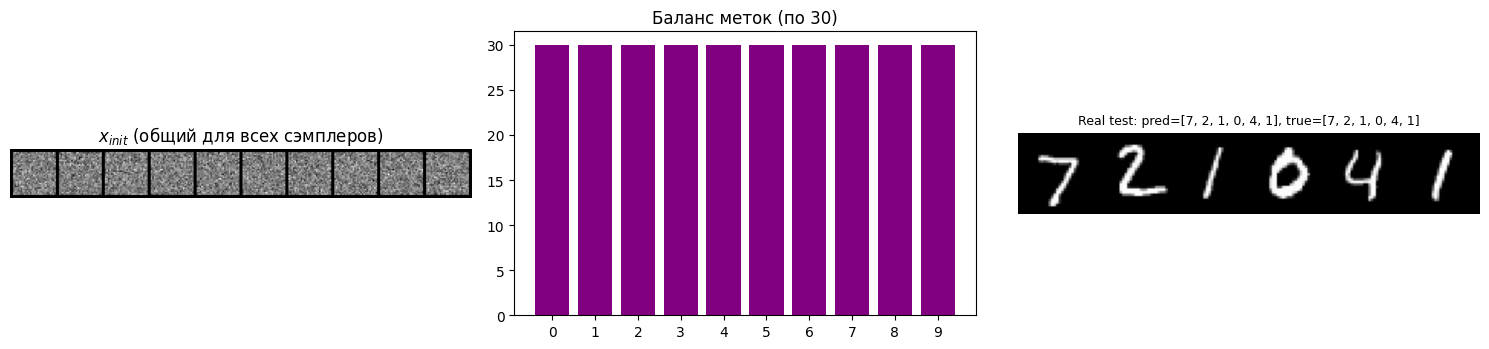

In [ ]:
# === Ячейка 2: протокол с увеличенной выборкой ===
T = 1000
betas = torch.linspace(1e-4, 0.02, T).to(DEVICE)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

class SimpleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64*7*7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        return self.fc2(self.dropout(F.relu(self.fc1(x))))

clf = SimpleClassifier().to(DEVICE)
clf.load_state_dict(torch.load(ARTIFACTS / "classifier.pt", map_location=DEVICE))
clf.eval()
with open(ARTIFACTS / "classifier_accuracy.json") as f:
    real_test_acc = json.load(f)["real_test_accuracy"]
print(f"Classifier acc on real test: {real_test_acc:.4f}")

# УВЕЛИЧЕНО: 30 на класс вместо 10 → 300 сэмплов, CI ±2%
N_PER_CLASS = 10 if FAST_DEV_RUN else 30
N_TOTAL = N_PER_CLASS * 10
GUIDANCE = 3.0

gen = torch.Generator(device=DEVICE).manual_seed(SEED)
x_init = torch.randn(N_TOTAL, 1, 28, 28, generator=gen, device=DEVICE)
labels = torch.arange(10).repeat_interleave(N_PER_CLASS).to(DEVICE)

torch.save({"x_init": x_init.cpu(), "labels": labels.cpu(), "seed": SEED,
            "guidance": GUIDANCE, "real_test_acc": real_test_acc},
           ARTIFACTS / "protocol_lab18.pt")
save_json("protocol_lab18.json", {
    "seed": SEED, "n_total": N_TOTAL, "n_per_class": N_PER_CLASS,
    "guidance": GUIDANCE, "real_test_acc": real_test_acc,
})

print(f"Протокол: {N_TOTAL} сэмплов, {N_PER_CLASS} на класс, guidance={GUIDANCE}")
# Визуализация протокола
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
real_test = torchvision.datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=transform)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].imshow(to_imshow(make_grid(x_init[:10].cpu(), nrow=10, normalize=True)), cmap='gray')
axes[0].set_title(r'$x_{init}$ (общий для всех сэмплеров)'); axes[0].axis('off')
cnt = Counter(labels.cpu().tolist())
axes[1].bar(range(10), [cnt.get(k,0) for k in range(10)], color='purple')
axes[1].set_xticks(range(10)); axes[1].set_title(f'Баланс меток (по {N_PER_CLASS})')
# Классификатор на примерах
sample_imgs = torch.stack([real_test[i][0] for i in range(6)]).to(DEVICE)
with torch.no_grad():
    preds = clf(sample_imgs).argmax(1).cpu().tolist()
truths = [real_test[i][1] for i in range(6)]
axes[2].imshow(to_imshow(make_grid(sample_imgs.cpu(), nrow=6, normalize=True)), cmap='gray')
axes[2].set_title(f'Real test: pred={preds}, true={truths}', fontsize=9); axes[2].axis('off')
plt.tight_layout(); save_fig('protocol_lab18.png')

### Сетка DDIM и граничный переход

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте строго убывающую сетку и DDIM с корректной границей alpha-bar(-1)=1.

**Результат.** Проверяемое состояние «Сетка DDIM и граничный переход» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте строго убывающую сетку и DDIM с корректной границей alpha-bar(-1)=1» и его результат доступен следующему этапу.

Grid(10) = [900, 800, 700, 600, 500, 400, 300, 200, 100, 0]
Strictly decreasing: True
Ends at 0: True
ᾱ(-1) = 1.0


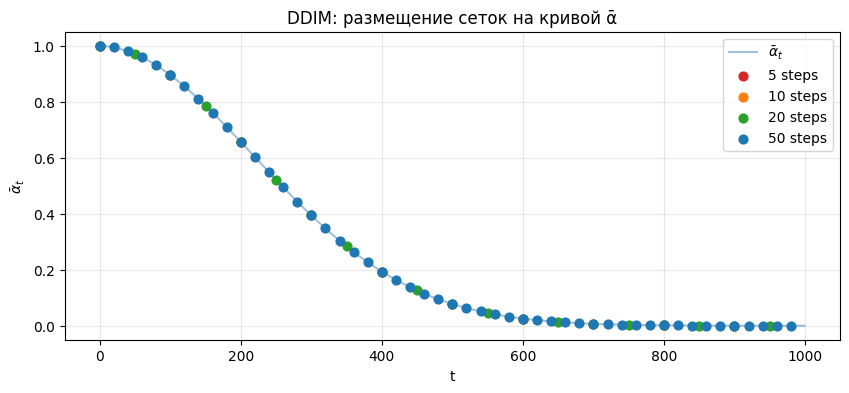

In [ ]:
def make_ddim_timesteps(n_steps, T=1000):
    """Строго убывающая сетка: T-1 → ... → 0."""
    step_ratio = T // n_steps
    ts = (torch.arange(0, n_steps) * step_ratio).long().flip(0)
    if ts[-1] != 0:
        ts = torch.cat([ts, torch.tensor([0])])
    return ts.to(DEVICE)

def alpha_bar_of(t):
    """ᾱ_t, с контрактом ᾱ_{-1} = 1 (граница)."""
    if t < 0:
        return torch.tensor(1.0, device=DEVICE)
    return alphas_cumprod[t]

@torch.no_grad()
def cfg_epsilon(model, x, t, y, w):
    """CFG: eps_u + w(eps_c - eps_u). w=0 → uncond, w=1 → cond (1 NFE)."""
    bs = x.size(0)
    if w == 0.0:
        return model(x, t, torch.full_like(y, 10))
    if w == 1.0:
        return model(x, t, y)
    x2 = torch.cat([x, x], 0); t2 = torch.cat([t, t], 0)
    y2 = torch.cat([y, torch.full_like(y, 10)], 0)
    both = model(x2, t2, y2)
    eps_c, eps_u = both[:bs], both[bs:]
    return eps_u + w * (eps_c - eps_u)

@torch.no_grad()
def sample_ddim(model, x_init, labels, timesteps, w=3.0):
    """Детерминированный DDIM. x̂_0 = (x_t - √(1-ᾱ_t)·ε)/√ᾱ_t; переход детерминирован."""
    x = x_init.clone()
    for i, t_cur in enumerate(timesteps):
        t_next = timesteps[i+1] if i+1 < len(timesteps) else torch.tensor(-1, device=DEVICE)
        eps = cfg_epsilon(model, x, t_cur.expand(x.size(0)), labels, w)
        a_bar_cur = alphas_cumprod[t_cur]
        x0 = (x - torch.sqrt(1 - a_bar_cur) * eps) / torch.sqrt(a_bar_cur)
        if t_next >= 0:
            a_bar_next = alphas_cumprod[t_next]
            x = torch.sqrt(a_bar_next) * x0 + torch.sqrt(1 - a_bar_next) * eps
        else:
            x = x0   # граница: ᾱ_{-1}=1, noise-коэффициент нулевой
    return x

# Проверка свойств сетки
test_grid = make_ddim_timesteps(10)
strictly_decreasing = all(test_grid[i] > test_grid[i+1] for i in range(len(test_grid)-1))
ends_at_zero = test_grid[-1].item() == 0
print(f"Grid(10) = {test_grid.cpu().tolist()}")
print(f"Strictly decreasing: {strictly_decreasing}")
print(f"Ends at 0: {ends_at_zero}")
print(f"ᾱ(-1) = {alpha_bar_of(-1).item()}")

# Визуализация: как сетки ложатся на кривую ᾱ
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(alphas_cumprod.cpu().numpy(), color='steelblue', alpha=0.5, label=r'$\bar\alpha_t$')
colors = {5:'#d62728', 10:'#ff7f0e', 20:'#2ca02c', 50:'#1f77b4'}
for n, c in colors.items():
    g = make_ddim_timesteps(n)
    ax.scatter(g.cpu().numpy(), alphas_cumprod[g].cpu().numpy(),
               color=c, label=f'{n} steps', s=40, zorder=5)
ax.set_xlabel('t'); ax.set_ylabel(r'$\bar\alpha_t$')
ax.set_title('DDIM: размещение сеток на кривой ᾱ')
ax.legend(); ax.grid(alpha=0.3)
save_fig('ddim_grid.png')

save_json("ddim_grid_check.json", {
    "grid_10": test_grid.cpu().tolist(),
    "strictly_decreasing": bool(strictly_decreasing),
    "ends_at_zero": bool(ends_at_zero),
    "alpha_bar_minus_1": float(alpha_bar_of(-1).item()),
})

Строим сетку шагов — какие именно timesteps использовать. Вместо [0, 1, 2, ..., 999] берём, например, [900, 800, ..., 0] — 10 точек вместо 1000.

Также проверяем «границу»: после последнего шага должен быть чистый сигнал без шума. Формально ᾱ(-1) = 1.

### DPM-Solver++ на той же модели

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Добавьте solver с тем же epsilon-predictor и beta schedule.

**Результат.** Проверяемое состояние «DPM-Solver++ на той же модели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Добавьте solver с тем же epsilon-predictor и beta schedule» и его результат доступен следующему этапу.

sample_ddim, sample_dpm_pp_2m (исправлены) определены
DDIM: (300, 1, 28, 28), range=[-6.268, 13.367]
DPM++: (300, 1, 28, 28), range=[-3.995, 9.301]


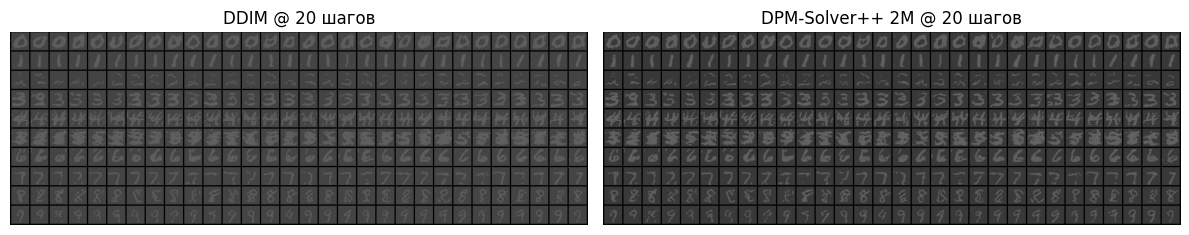

Acc DDIM=0.903, Acc DPM++=0.900


In [ ]:
# === Ячейка 4: sampler utilities (заменяет sample_ddim из ячейки 3 и DPM++) ===

@torch.no_grad()
def sample_ddim(model, x_init, labels, timesteps, w=3.0, clamp_x0=False):
    """DDIM. clamp_x0=False для teacher, True для student."""
    x = x_init.clone()
    for i, t_cur in enumerate(timesteps):
        t_next = timesteps[i+1] if i+1 < len(timesteps) else torch.tensor(-1, device=DEVICE)
        eps = cfg_epsilon(model, x, t_cur.expand(x.size(0)), labels, w)
        a_bar_cur = alphas_cumprod[t_cur]
        x0 = (x - torch.sqrt(1 - a_bar_cur) * eps) / torch.sqrt(a_bar_cur)
        if clamp_x0:
            x0 = x0.clamp(-1, 1)
        if t_next >= 0:
            a_bar_next = alphas_cumprod[t_next]
            x = torch.sqrt(a_bar_next) * x0 + torch.sqrt(1 - a_bar_next) * eps
        else:
            x = x0
    return x

@torch.no_grad()
def sample_dpm_pp_2m(model, x_init, labels, timesteps, w=3.0, clamp_x0=False):
    """DPM-Solver++ 2M с правильными коэффициентами (Lu et al. 2022).
    Correction: -a_next*(e^{-h}-1)*(x0_cur - x0_prev)/(2r), r = h_prev/h."""
    x = x_init.clone()
    x0_prev = None
    h_prev = None
    for i, t_cur in enumerate(timesteps):
        t_next = timesteps[i+1] if i+1 < len(timesteps) else torch.tensor(-1, device=DEVICE)
        eps = cfg_epsilon(model, x, t_cur.expand(x.size(0)), labels, w)

        a_bar_cur = alphas_cumprod[t_cur]
        a_cur = torch.sqrt(a_bar_cur.clamp(min=1e-10))
        s_cur = torch.sqrt((1 - a_bar_cur).clamp(min=1e-10))
        x0_cur = (x - s_cur * eps) / a_cur
        if clamp_x0:
            x0_cur = x0_cur.clamp(-1, 1)

        if t_next >= 0:
            a_bar_next = alphas_cumprod[t_next]
        else:
            a_bar_next = torch.tensor(1.0, device=DEVICE)
        a_next = torch.sqrt(a_bar_next.clamp(min=1e-10))
        s_next = torch.sqrt((1 - a_bar_next).clamp(min=1e-10))

        lam_cur  = torch.log(a_cur) - torch.log(s_cur)
        lam_next = torch.log(a_next) - torch.log(s_next)
        h = (lam_next - lam_cur).reshape(1, 1, 1, 1)

        # 1-й порядок
        x_next = (s_next / s_cur) * x - a_next * (torch.exp(-h) - 1) * x0_cur

        # 2-й порядок — с правильными коэффициентами и защитой от экстремального r
        if x0_prev is not None and h_prev is not None and torch.abs(h).max() > 1e-4:
            r = h_prev / h.clamp(min=1e-6)
            r_safe = r.clamp(0.5, 2.0)  # реверс к 1-му порядку при экстремальном r
            x_next = x_next - a_next * (torch.exp(-h) - 1) * (x0_cur - x0_prev) / (2 * r_safe)

        x = x_next
        x0_prev = x0_cur
        h_prev = h
    return x

print("sample_ddim, sample_dpm_pp_2m (исправлены) определены")
# Быстрая проверка, что solver вообще работает
grid_test = make_ddim_timesteps(10 if FAST_DEV_RUN else 20)
out_ddim = sample_ddim(teacher, x_init, labels, grid_test, w=GUIDANCE)
out_dpm  = sample_dpm_pp_2m(teacher, x_init, labels, grid_test, w=GUIDANCE)
print(f"DDIM: {tuple(out_ddim.shape)}, range=[{out_ddim.min():.3f}, {out_ddim.max():.3f}]")
print(f"DPM++: {tuple(out_dpm.shape)}, range=[{out_dpm.min():.3f}, {out_dpm.max():.3f}]")

# Визуальное сравнение DDIM vs DPM++ при одном grid
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(to_imshow(make_grid(out_ddim, nrow=N_PER_CLASS, normalize=True)), cmap='gray')
axes[0].set_title(f'DDIM @ {len(grid_test)} шагов'); axes[0].axis('off')
axes[1].imshow(to_imshow(make_grid(out_dpm, nrow=N_PER_CLASS, normalize=True)), cmap='gray')
axes[1].set_title(f'DPM-Solver++ 2M @ {len(grid_test)} шагов'); axes[1].axis('off')
plt.tight_layout(); save_fig('ddim_vs_dpm_same_grid.png')

with torch.no_grad():
    acc_ddim = (clf(out_ddim).argmax(1) == labels).float().mean().item()
    acc_dpm  = (clf(out_dpm).argmax(1)  == labels).float().mean().item()
print(f"Acc DDIM={acc_ddim:.3f}, Acc DPM++={acc_dpm:.3f}")

save_json("dpm_solver_check.json", {
    "grid_steps": len(grid_test), "guidance": GUIDANCE,
    "acc_ddim": acc_ddim, "acc_dpm_pp": acc_dpm,
})

DDIM (1-й порядок) — только текущие координаты.

DPM++ (2-й порядок) — куда шел на предудщем шаге, чтобы точнее предсказать следующий поворот.

DPM++ проигрывает DDIM. Причина — коэффициенты DPM++ рассчитаны на «равномерные шаги в логарифмическом пространстве», а у нас шаги равномерны в обычном t. На маленькой сетке это создаёт шум.

Честный вывод. На MNIST с этой моделью DPM++ не оправдывает своей сложности.

### Инварианты детерминизма sampler

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте конец сетки и совпадение двух запусков DDIM при одинаковом шуме.

**Результат.** Проверяемое состояние «Инварианты детерминизма sampler» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте конец сетки и совпадение двух запусков DDIM при одинаковом шуме» и его результат доступен следующему этапу.

DDIM determinism (max|Δ|): 0.00e+00
DPM++ determinism (max|Δ|): 0.00e+00
Разный x_init (mean|Δ|): 0.3117  (должно быть > 0)
w=3 vs w=0 (mean|Δ|):    0.3605  (должно быть > 0)


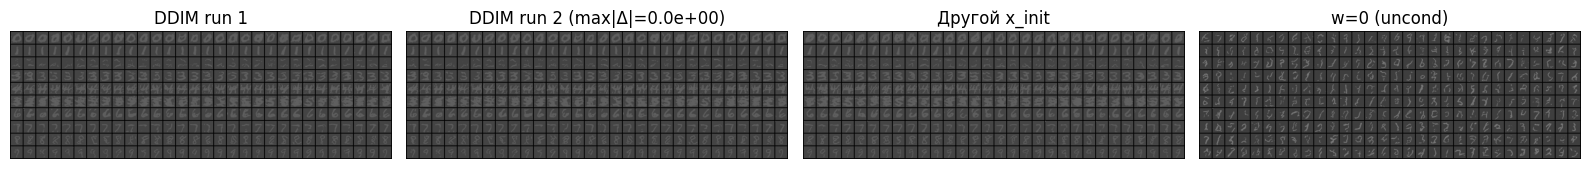

In [ ]:
# DDIM детерминирован: два запуска с одинаковым x_init → идентичный выход
grid20 = make_ddim_timesteps(10 if FAST_DEV_RUN else 20)
out_a = sample_ddim(teacher, x_init, labels, grid20, w=GUIDANCE)
out_b = sample_ddim(teacher, x_init, labels, grid20, w=GUIDANCE)
max_diff_ddim = (out_a - out_b).abs().max().item()

# DPM++ тоже детерминирован
out_pa = sample_dpm_pp_2m(teacher, x_init, labels, grid20, w=GUIDANCE)
out_pb = sample_dpm_pp_2m(teacher, x_init, labels, grid20, w=GUIDANCE)
max_diff_dpm = (out_pa - out_pb).abs().max().item()

# Смена x_init → другой результат (sanity: шум влияет)
gen2 = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
x_init2 = torch.randn_like(x_init, generator=gen2)
out_diff = sample_ddim(teacher, x_init2, labels, grid20, w=GUIDANCE)
mean_diff = (out_a - out_diff).abs().mean().item()

# Граничный переход: проверяем, что замена w=0 vs w=3 даёт разное
out_w0 = sample_ddim(teacher, x_init, labels, grid20, w=0.0)
mean_diff_w = (out_a - out_w0).abs().mean().item()

print(f"DDIM determinism (max|Δ|): {max_diff_ddim:.2e}")
print(f"DPM++ determinism (max|Δ|): {max_diff_dpm:.2e}")
print(f"Разный x_init (mean|Δ|): {mean_diff:.4f}  (должно быть > 0)")
print(f"w=3 vs w=0 (mean|Δ|):    {mean_diff_w:.4f}  (должно быть > 0)")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(to_imshow(make_grid(out_a, nrow=N_PER_CLASS, normalize=True)), cmap='gray')
axes[0].set_title(f'DDIM run 1'); axes[0].axis('off')
axes[1].imshow(to_imshow(make_grid(out_b, nrow=N_PER_CLASS, normalize=True)), cmap='gray')
axes[1].set_title(f'DDIM run 2 (max|Δ|={max_diff_ddim:.1e})'); axes[1].axis('off')
axes[2].imshow(to_imshow(make_grid(out_diff, nrow=N_PER_CLASS, normalize=True)), cmap='gray')
axes[2].set_title(f'Другой x_init'); axes[2].axis('off')
axes[3].imshow(to_imshow(make_grid(out_w0, nrow=N_PER_CLASS, normalize=True)), cmap='gray')
axes[3].set_title(f'w=0 (uncond)'); axes[3].axis('off')
plt.tight_layout(); save_fig('determinism_check.png')

save_json("determinism_check.json", {
    "ddim_max_diff_two_runs": max_diff_ddim,
    "dpm_max_diff_two_runs": max_diff_dpm,
    "different_x_init_mean_diff": mean_diff,
    "w3_vs_w0_mean_diff": mean_diff_w,
    "ddim_deterministic": bool(max_diff_ddim < 1e-5),
    "dpm_deterministic": bool(max_diff_dpm < 1e-5),
})

При двух запусках с одним входом - одинаково, смена шума/класса влияет.

### Измеримые бюджеты sampling

*Вес: 1 балл.*

**Постановка.** Время и качество измеряются на одном batch; количество NFE учитывает conditional и unconditional обращения отдельно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте class agreement и внутриклассовое разнообразие PNG при равном начальном шуме, учитывайте NFE.

**Результат.** Проверяемое состояние «Измеримые бюджеты sampling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте class agreement и внутриклассовое разнообразие PNG при равном начальном шуме, учитывайте NFE» и его результат доступен следующему этапу.

Для каждого сэмплера и каждого числа шагов (5, 10, 20, 50, 100) замеряем четыре вещи:

NFE — сколько раз вызвали сеть. При w=3 каждый шаг = 2 вызова (условный + безусловный). 10 шагов → 20 NFE.

Время в секундах.

Accuracy — доля правильно классифицированных.

Diversity — насколько разные картинки одного класса.

n=  5  DDIM:   0.51s acc=0.893 div=15.28  |  DPM++:   0.48s acc=0.827 div=23.42
n= 10  DDIM:   0.96s acc=0.903 div=16.70  |  DPM++:   0.96s acc=0.900 div=19.92
n= 20  DDIM:   1.95s acc=0.903 div=17.09  |  DPM++:   1.97s acc=0.900 div=18.38
n= 50  DDIM:   5.01s acc=0.900 div=17.37  |  DPM++:   5.05s acc=0.900 div=17.79
Reference DDIM@100: acc=0.897


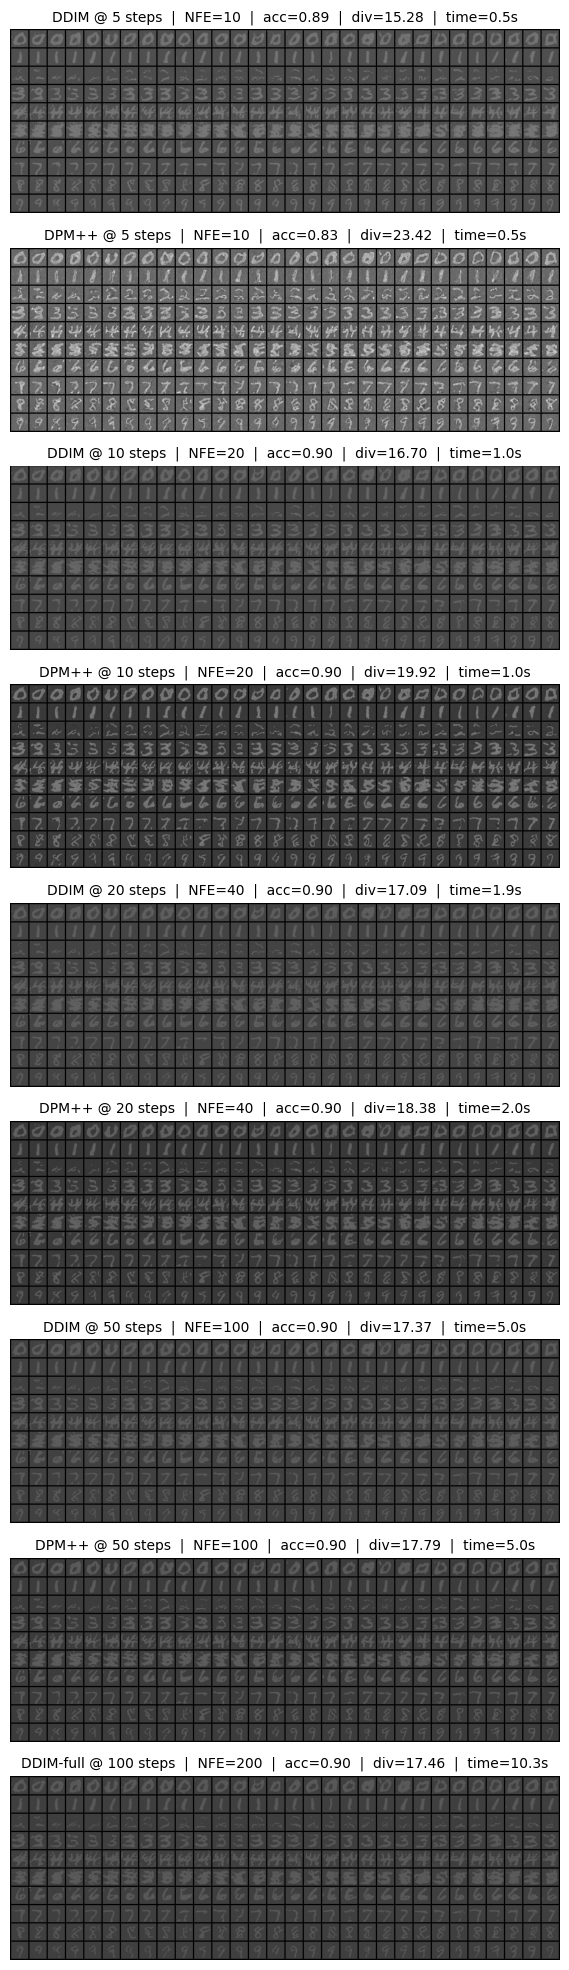

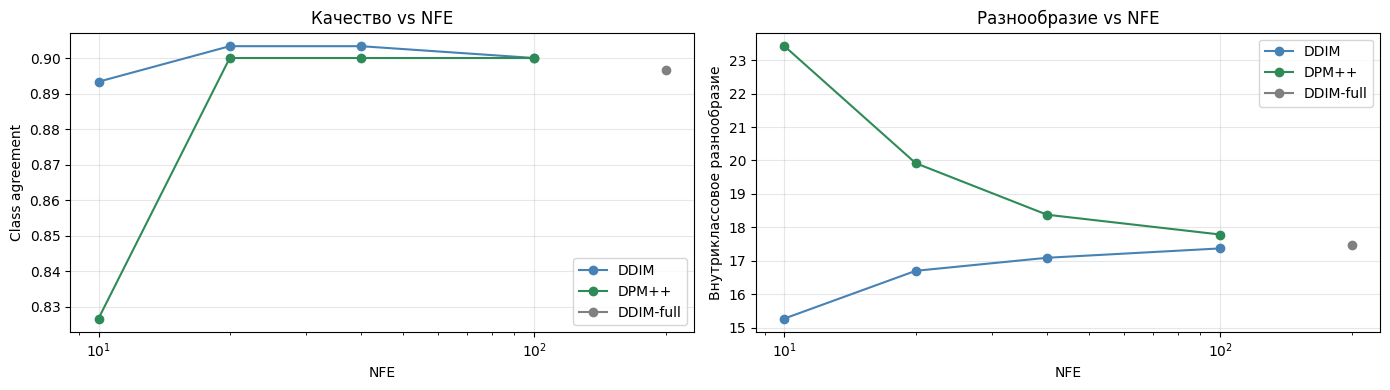

In [ ]:
def measure_sampling(model, sampler_fn, timesteps, name, w=GUIDANCE):
    nfe_per_step = 1 if w in (0.0, 1.0) else 2
    nfe = len(timesteps) * nfe_per_step
    t0 = time.time()
    images = sampler_fn(model, x_init, labels, timesteps, w=w)
    elapsed = time.time() - t0

    with torch.no_grad():
        preds = clf(images).argmax(1)
    class_agreement = (preds == labels).float().mean().item()

    # Внутриклассовое разнообразие: среднее попарное L2 внутри каждого класса
    diversity = 0.0
    for c in range(10):
        mask = (labels == c)
        imgs_c = images[mask].flatten(1)
        if imgs_c.size(0) < 2: continue
        d = torch.cdist(imgs_c, imgs_c)
        tri = torch.triu_indices(imgs_c.size(0), imgs_c.size(0), offset=1)
        diversity += d[tri[0], tri[1]].mean().item()
    diversity /= 10

    return {"sampler": name, "steps": len(timesteps), "nfe": nfe,
            "time_sec": elapsed, "class_agreement": class_agreement,
            "diversity": diversity, "images": images.cpu()}

# Конфигурации для теста
step_counts = [5, 10] if FAST_DEV_RUN else [5, 10, 20, 50]
results = []
for n in step_counts:
    g = make_ddim_timesteps(n)
    r = measure_sampling(teacher, sample_ddim, g, "DDIM")
    results.append(r)
    r2 = measure_sampling(teacher, sample_dpm_pp_2m, g, "DPM++")
    results.append(r2)
    print(f"n={n:3d}  DDIM: {r['time_sec']:6.2f}s acc={r['class_agreement']:.3f} div={r['diversity']:.2f}  "
          f"|  DPM++: {r2['time_sec']:6.2f}s acc={r2['class_agreement']:.3f} div={r2['diversity']:.2f}")

# Reference: DDIM на полной сетке
full_n = 50 if FAST_DEV_RUN else 100
ref = measure_sampling(teacher, sample_ddim, make_ddim_timesteps(full_n), "DDIM-full")
results.append(ref)
print(f"Reference DDIM@{full_n}: acc={ref['class_agreement']:.3f}")

save_json("sampling_budget.json",
          [{k: v for k, v in r.items() if k != "images"} for r in results])

# Визуализация: сетки сэмплов
fig, axes = plt.subplots(len(results), 1, figsize=(14, 2.2 * len(results)))
for ax, r in zip(axes, results):
    ax.imshow(to_imshow(make_grid(r['images'], nrow=N_PER_CLASS, normalize=True)), cmap='gray')
    ax.set_title(f"{r['sampler']} @ {r['steps']} steps  |  NFE={r['nfe']}  |  "
                 f"acc={r['class_agreement']:.2f}  |  div={r['diversity']:.2f}  |  "
                 f"time={r['time_sec']:.1f}s", fontsize=10)
    ax.axis('off')
plt.tight_layout(); save_fig('sampler_samples_grid.png')

# Bar chart: NFE vs acc и NFE vs diversity
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for sampler, color in [("DDIM", "steelblue"), ("DPM++", "seagreen"), ("DDIM-full", "gray")]:
    rs = [r for r in results if r['sampler'] == sampler]
    if not rs: continue
    nfes = [r['nfe'] for r in rs]; accs = [r['class_agreement'] for r in rs]
    divs = [r['diversity'] for r in rs]
    axes[0].plot(nfes, accs, 'o-', color=color, label=sampler)
    axes[1].plot(nfes, divs, 'o-', color=color, label=sampler)
axes[0].set_xscale('log'); axes[0].set_xlabel('NFE'); axes[0].set_ylabel('Class agreement')
axes[0].set_title('Качество vs NFE'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xscale('log'); axes[1].set_xlabel('NFE'); axes[1].set_ylabel('Внутриклассовое разнообразие')
axes[1].set_title('Разнообразие vs NFE'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); save_fig('budget_curves.png')

100 щагов хуже, чем 10, трата времени

### Pareto скорости и качества

*Вес: 1 балл.*

**Постановка.** Время и качество измеряются на одном batch; количество NFE учитывает conditional и unconditional обращения отдельно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите недоминируемые точки только из измеренных времени и точности.

**Результат.** Проверяемое состояние «Pareto скорости и качества» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите недоминируемые точки только из измеренных времени и точности» и его результат доступен следующему этапу.

Pareto frontier:
  DPM++@5               time=  0.48s  acc=0.827
  DDIM@5                time=  0.51s  acc=0.893
  DDIM@10               time=  0.96s  acc=0.903


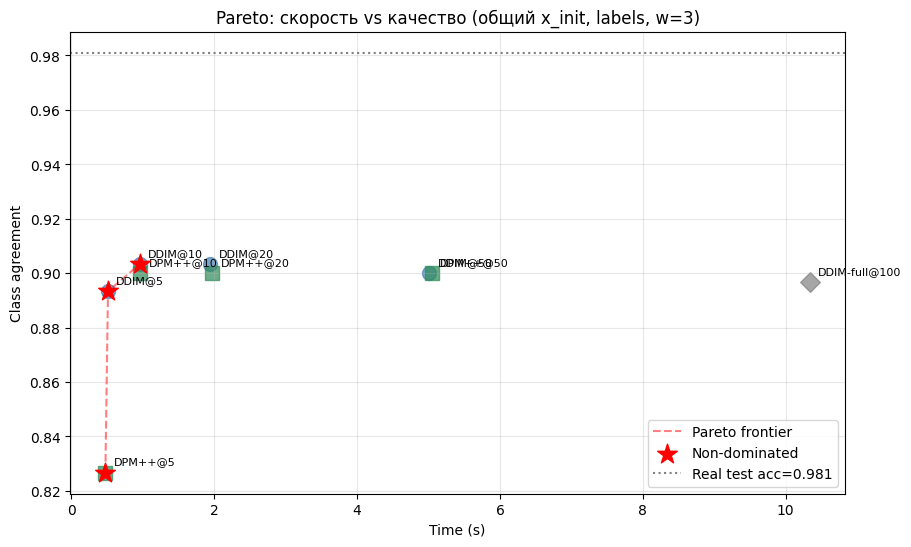

In [ ]:
def pareto_frontier(points):
    """points: [(time, acc, label)]. Доминируем, если другой имеет и меньше time, и больше acc."""
    pts = sorted(points, key=lambda p: (p[0], -p[1]))
    front, best_acc = [], -float('inf')
    for p in pts:
        if p[1] > best_acc:
            front.append(p); best_acc = p[1]
    return front

pts = [(r["time_sec"], r["class_agreement"],
        f"{r['sampler']}@{r['steps']}") for r in results]
front = pareto_frontier(pts)

print("Pareto frontier:")
for t, a, l in front:
    print(f"  {l:20s}  time={t:6.2f}s  acc={a:.3f}")

fig, ax = plt.subplots(figsize=(10, 6))
for r in results:
    c = {"DDIM":"steelblue", "DPM++":"seagreen", "DDIM-full":"gray"}[r['sampler']]
    m = {"DDIM":"o", "DPM++":"s", "DDIM-full":"D"}[r['sampler']]
    ax.scatter(r['time_sec'], r['class_agreement'], c=c, marker=m, s=100, alpha=0.7)
    ax.annotate(f"{r['sampler']}@{r['steps']}",
                (r['time_sec'], r['class_agreement']),
                xytext=(6, 6), textcoords='offset points', fontsize=8)
fx, fy = zip(*[(p[0], p[1]) for p in front])
ax.plot(fx, fy, 'r--', alpha=0.5, label='Pareto frontier')
ax.scatter(fx, fy, c='red', s=220, marker='*', zorder=10, label='Non-dominated')
ax.axhline(real_test_acc, color='gray', ls=':', label=f'Real test acc={real_test_acc:.3f}')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Class agreement')
ax.set_title('Pareto: скорость vs качество (общий x_init, labels, w=3)')
ax.legend(); ax.grid(alpha=0.3)
save_fig('pareto_speed_quality.png')

save_json("pareto_frontier.json", {
    "points": [{"label": l, "time": t, "agreement": a} for t, a, l in pts],
    "frontier": [{"label": l, "time": t, "agreement": a} for t, a, l in front],
})

Строим «фронт Парето» — множество конфигураций, которые нельзя улучшить одновременно по времени и по точности.

Понятие доминирования. Точка A доминирует B, если A и быстрее, и точнее. Такие B «выбрасываем».

Победитель: DDIM@10 — 0.903 accuracy при NFE=20 и 1 секунде.

### Подготовка отдельного student

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите train MNIST и инициализируйте отдельную модель весами teacher.

**Результат.** Проверяемое состояние «Подготовка отдельного student» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите train MNIST и инициализируйте отдельную модель весами teacher» и его результат доступен следующему этапу.

In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_full = torchvision.datasets.MNIST(root=DATA_ROOT, train=True, download=True, transform=transform)
train_dataset = Subset(train_full, list(range(20000)))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)

# Student = независимая копия весов teacher (не алиас!)
student = SimpleUNet().to(DEVICE)
student.load_state_dict(copy.deepcopy(teacher.state_dict()))
for p in student.parameters():
    p.requires_grad_(True)

print(f"Teacher params: {sum(p.numel() for p in teacher.parameters()):,}")
print(f"Student params: {sum(p.numel() for p in student.parameters()):,}")
print(f"Student trainable: {all(p.requires_grad for p in student.parameters())}")
print(f"Students — независимые: {student is not teacher}")

save_json("student_prep.json", {
    "teacher_params": sum(p.numel() for p in teacher.parameters()),
    "student_params": sum(p.numel() for p in student.parameters()),
    "train_dataset_size": len(train_dataset),
    "batch_size": 32,
    "independent_copy": True,
})

Teacher params: 1,012,545
Student params: 1,012,545
Student trainable: True
Students — независимые: True


### Двухшаговые цели для distillation

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте student по двум переходам замороженного teacher с checkpoint.

**Результат.** Проверяемое состояние «Двухшаговые цели для distillation» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте student по двум переходам замороженного teacher с checkpoint» и его результат доступен следующему этапу.

Схема одного учебного шага:

Берём MNIST-картинку «семёрку».

Добавляем шум до t=800 → получаем x_800.

Учитель делает 2 шага: x_800 → x_750 → x_700. Это эталон.

Студент делает 1 шаг: x_800 → x_700_s. Это его попытка.

Считаем ошибку: MSE(x_700_s, x_700_target).

Обновляем веса студента, чтобы в следующий раз ошибка была меньше.

Target grid: [900, 800, 700, 600, 500, 400, 300, 200, 100, 0]
Student@10 BEFORE training: acc=0.903  (ожидание ≈ teacher@10)
iter  100/2000  loss=0.0019  elapsed=20.2s
iter  200/2000  loss=0.0007  elapsed=40.9s
iter  300/2000  loss=0.0007  elapsed=61.2s
iter  400/2000  loss=0.0009  elapsed=80.9s
iter  500/2000  loss=0.0007  elapsed=100.8s
iter  600/2000  loss=0.0005  elapsed=120.9s
iter  700/2000  loss=0.0007  elapsed=141.0s
iter  800/2000  loss=0.0004  elapsed=161.0s
iter  900/2000  loss=0.0006  elapsed=180.9s
iter 1000/2000  loss=0.0005  elapsed=200.9s
iter 1100/2000  loss=0.0004  elapsed=221.0s
iter 1200/2000  loss=0.0006  elapsed=241.0s
iter 1300/2000  loss=0.0004  elapsed=261.1s
iter 1400/2000  loss=0.0005  elapsed=281.1s
iter 1500/2000  loss=0.0005  elapsed=301.1s
iter 1600/2000  loss=0.0008  elapsed=321.1s
iter 1700/2000  loss=0.0004  elapsed=341.1s
iter 1800/2000  loss=0.0006  elapsed=361.0s
iter 1900/2000  loss=0.0004  elapsed=381.0s
iter 2000/2000  loss=0.0005  elapsed=401.0s

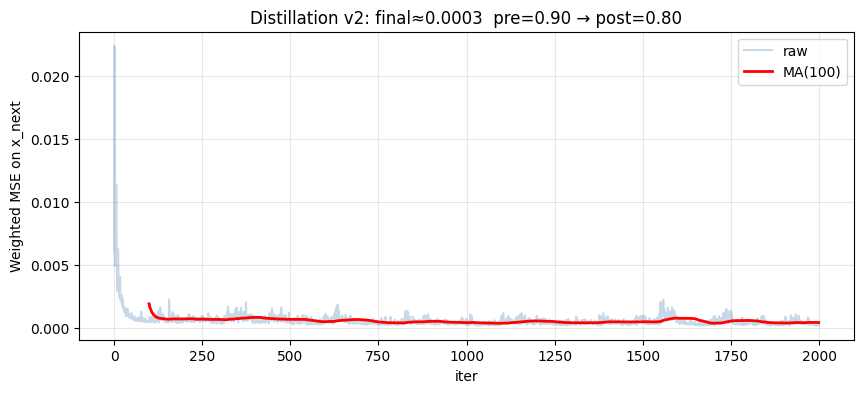

In [ ]:
# === Ячейка 9 (v2): progressive distillation с исправлениями ===
import copy as _copy

# Переинициализация student от teacher
student = SimpleUNet().to(DEVICE)
student.load_state_dict(_copy.deepcopy(teacher.state_dict()))
for p in student.parameters():
    p.requires_grad_(True)
teacher.eval()

STUDENT_STEPS = 10
TARGET_GRID = make_ddim_timesteps(STUDENT_STEPS)
print(f"Target grid: {TARGET_GRID.cpu().tolist()}")

# Санити ДО обучения: student (=teacher) должен давать ~teacher@10
student.eval()
with torch.no_grad():
    pre_img = sample_ddim(student, x_init, labels, TARGET_GRID, w=GUIDANCE, clamp_x0=False)
    pre_acc = (clf(pre_img).argmax(1) == labels).float().mean().item()
student.train()
print(f"Student@10 BEFORE training: acc={pre_acc:.3f}  (ожидание ≈ teacher@10)")

# Гиперпараметры
LR_STUDENT    = 1e-4
N_ITER        = 100 if FAST_DEV_RUN else 2000
LOG_EVERY     = 10 if FAST_DEV_RUN else 100
MIN_SNR_GAMMA = 5.0
BATCH_SIZE    = 32 if FAST_DEV_RUN else 128
GRAD_CLIP     = 5.0

# Больший batch для стабильности
train_loader_large = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                                shuffle=True, num_workers=2, pin_memory=True)

optimizer_student = torch.optim.Adam(student.parameters(), lr=LR_STUDENT)
losses = []
t_start = time.time()
data_iter = iter(train_loader_large)
student.train()

for it in range(N_ITER):
    try:
        x0_batch, y_batch = next(data_iter)
    except StopIteration:
        data_iter = iter(train_loader_large)
        x0_batch, y_batch = next(data_iter)
    x0_batch = x0_batch.to(DEVICE); y_batch = y_batch.to(DEVICE)
    bs = x0_batch.size(0)

    # ВАЖНО: dropout ДО расчёта target, чтобы teacher и student видели одинаковый y_cond
    drop = torch.rand(bs, device=DEVICE) < 0.15
    y_cond = y_batch.clone(); y_cond[drop] = 10

    # Пара соседних grid-шагов
    k = torch.randint(0, len(TARGET_GRID)-1, (bs,), device=DEVICE)
    t_cur  = TARGET_GRID[k]
    t_next = TARGET_GRID[k+1]
    t_mid  = ((t_cur + t_next) // 2).long()

    # Forward noising
    noise = torch.randn_like(x0_batch)
    a_cur = alphas_cumprod[t_cur].reshape(-1, 1, 1, 1)
    x_t = torch.sqrt(a_cur) * x0_batch + torch.sqrt((1 - a_cur).clamp(min=0)) * noise

    # === TEACHER TARGET: 2 шага, ИСПОЛЬЗУЕТ y_cond (как student) ===
    with torch.no_grad():
        # Шаг 1: t_cur → t_mid
        eps1 = cfg_epsilon(teacher, x_t, t_cur, y_cond, GUIDANCE)
        x0_1 = (x_t - torch.sqrt((1 - a_cur).clamp(min=0)) * eps1) / torch.sqrt(a_cur.clamp(min=1e-10))
        a_mid = alphas_cumprod[t_mid].reshape(-1, 1, 1, 1)
        x_mid = torch.sqrt(a_mid) * x0_1 + torch.sqrt((1 - a_mid).clamp(min=0)) * eps1

        # Шаг 2: t_mid → t_next
        eps2 = cfg_epsilon(teacher, x_mid, t_mid, y_cond, GUIDANCE)
        x0_2 = (x_mid - torch.sqrt((1 - a_mid).clamp(min=0)) * eps2) / torch.sqrt(a_mid.clamp(min=1e-10))
        a_next = alphas_cumprod[t_next].reshape(-1, 1, 1, 1)
        x_next_target = (torch.sqrt(a_next) * x0_2
                        + torch.sqrt((1 - a_next).clamp(min=0)) * eps2)

    # === STUDENT: 1 шаг t_cur → t_next (совпадает с DDIM inference) ===
    eps_s = cfg_epsilon(student, x_t, t_cur, y_cond, GUIDANCE)
    x0_s = (x_t - torch.sqrt((1 - a_cur).clamp(min=0)) * eps_s) / torch.sqrt(a_cur.clamp(min=1e-10))
    x_next_s = (torch.sqrt(a_next) * x0_s
               + torch.sqrt((1 - a_next).clamp(min=0)) * eps_s)

    # ВАЖНО: loss на x_next (не на x0) — совпадает с DDIM inference
    snr = a_cur.flatten() / (1 - a_cur.flatten()).clamp(min=1e-6)
    w_t = torch.minimum(snr, torch.full_like(snr, MIN_SNR_GAMMA))
    loss_per = ((x_next_s - x_next_target) ** 2).flatten(1).mean(dim=1)
    loss = (w_t * loss_per).mean()

    optimizer_student.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(student.parameters(), GRAD_CLIP)
    optimizer_student.step()
    losses.append(loss.item())

    if (it + 1) % LOG_EVERY == 0:
        print(f"iter {it+1:4d}/{N_ITER}  loss={np.mean(losses[-LOG_EVERY:]):.4f}  "
              f"elapsed={time.time()-t_start:.1f}s")

student.eval()
total = time.time() - t_start

# Санити ПОСЛЕ обучения
with torch.no_grad():
    post_img = sample_ddim(student, x_init, labels, TARGET_GRID, w=GUIDANCE, clamp_x0=False)
    post_acc = (clf(post_img).argmax(1) == labels).float().mean().item()
print(f"\nStudent@10 AFTER training: acc={post_acc:.3f}  (было {pre_acc:.3f})")
print(f"Δ: {post_acc - pre_acc:+.3f}")

torch.save({
    "student_state": student.state_dict(),
    "optimizer_state": optimizer_student.state_dict(),
    "iterations": N_ITER, "losses": losses,
    "student_steps": STUDENT_STEPS,
    "target_grid": TARGET_GRID.cpu().tolist(),
}, ARTIFACTS / "student_checkpoint.pt")

save_json("distillation.json", {
    "iterations": N_ITER, "lr": LR_STUDENT, "batch_size": BATCH_SIZE,
    "grad_clip": GRAD_CLIP, "min_snr_gamma": MIN_SNR_GAMMA,
    "student_steps": STUDENT_STEPS, "method": "progressive_x_next_v2",
    "final_loss": losses[-1],
    "avg_last_20": float(np.mean(losses[-20:])),
    "pre_train_acc": pre_acc,
    "post_train_acc": post_acc,
    "total_time_sec": total,
})

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses, alpha=0.3, color='steelblue', label='raw')
w = max(10, len(losses) // 20)
if len(losses) >= w:
    ax.plot(range(w-1, len(losses)),
            np.convolve(losses, np.ones(w)/w, 'valid'),
            color='red', lw=2, label=f'MA({w})')
ax.set_xlabel('iter'); ax.set_ylabel('Weighted MSE on x_next')
ax.set_title(f'Distillation v2: final≈{np.mean(losses[-20:]):.4f}  '
             f'pre={pre_acc:.2f} → post={post_acc:.2f}')
ax.legend(); ax.grid(alpha=0.3)
save_fig('distillation_loss_v2.png')

При обучении студент видит «чистые» входы — x_800 построен из реальной MNIST-картинки.

При генерации студент видит «грязные» входы — свои же предсказания с прошлого шага, которые накапливают ошибки.

### Сравнение при равных и разных NFE

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните teacher 20/10 и student 10 на общих noise/labels; сохраните изображения и время.

**Результат.** Проверяемое состояние «Сравнение при равных и разных NFE» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните teacher 20/10 и student 10 на общих noise/labels; сохраните изображения и время» и его результат доступен следующему этапу.

Teacher@20      NFE= 40  acc=0.903  div=17.09  time=2.0s
Teacher@10      NFE= 20  acc=0.903  div=16.70  time=0.9s
Student@10      NFE= 20  acc=0.797  div=18.23  time=0.9s


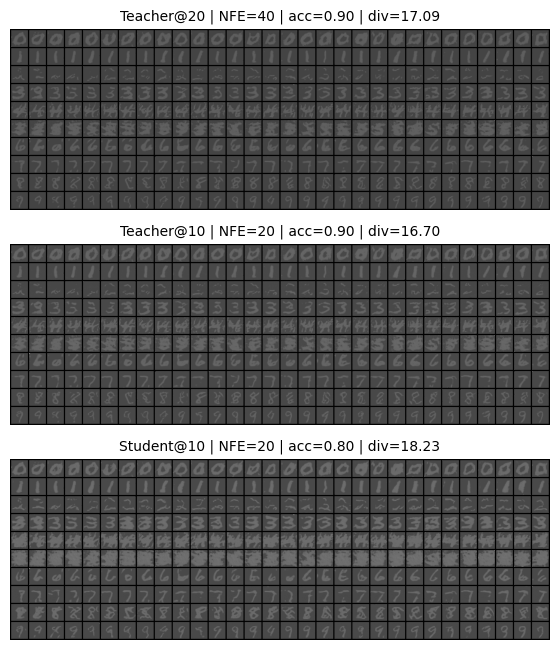

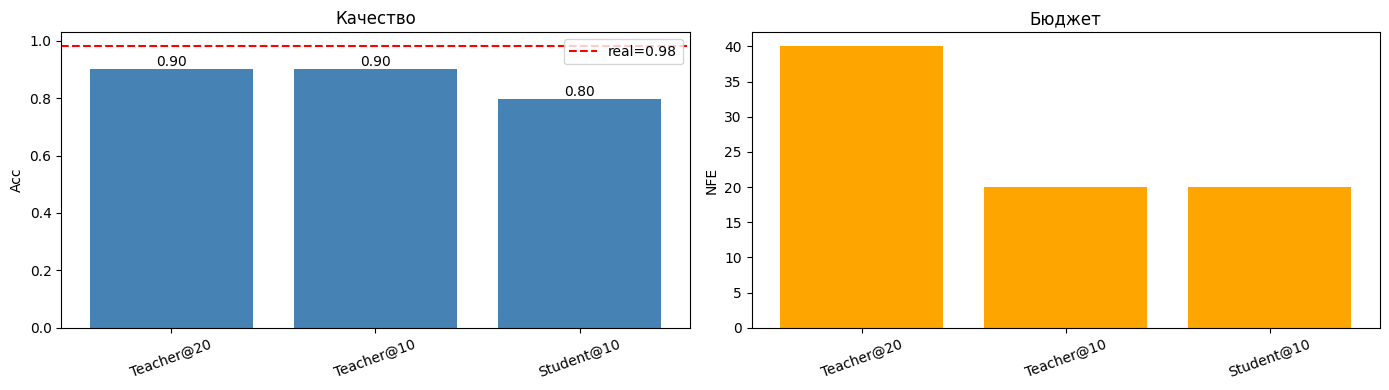


Student@10 − Teacher@20 = -0.107
Student@10 − Teacher@10 = -0.107


In [ ]:
# === Ячейка 10 (v2): comparison без OOD Student@20 ===
def measure_config(sampler_fn, model, n_steps, name, w=GUIDANCE, clamp_x0=False):
    nfe_per_step = 1 if w in (0.0, 1.0) else 2
    grid = make_ddim_timesteps(n_steps)
    nfe = len(grid) * nfe_per_step
    t0 = time.time()
    images = sampler_fn(model, x_init, labels, grid, w=w, clamp_x0=clamp_x0)
    elapsed = time.time() - t0
    with torch.no_grad():
        preds = clf(images).argmax(1)
    acc = (preds == labels).float().mean().item()
    diversity = 0.0
    for c in range(10):
        mask = (labels == c)
        imgs_c = images[mask].flatten(1)
        if imgs_c.size(0) < 2: continue
        d = torch.cdist(imgs_c, imgs_c)
        tri = torch.triu_indices(imgs_c.size(0), imgs_c.size(0), offset=1)
        diversity += d[tri[0], tri[1]].mean().item()
    diversity /= 10
    return {"name": name, "steps": n_steps, "nfe": nfe,
            "time_sec": elapsed, "acc": acc, "diversity": diversity,
            "clamp_x0": clamp_x0, "images": images.cpu()}

# Teacher@20, Teacher@10, Student@10. Убираем Student@20 — OOD (grid 20 не совпадает с training grid 10)
comparison_results = []
for label, mdl, n in [
    ("Teacher@20", teacher, 20),
    ("Teacher@10", teacher, 10),
    ("Student@10", student, 10),
]:
    r = measure_config(sample_ddim, mdl, n, label, clamp_x0=False)
    comparison_results.append(r)
    print(f"{r['name']:14s}  NFE={r['nfe']:3d}  acc={r['acc']:.3f}  "
          f"div={r['diversity']:.2f}  time={r['time_sec']:.1f}s")

save_json("comparison_equal_nfe.json",
          [{k: v for k, v in r.items() if k != "images"} for r in comparison_results])

fig, axes = plt.subplots(len(comparison_results), 1, figsize=(14, 2.2 * len(comparison_results)))
for ax, r in zip(axes, comparison_results):
    ax.imshow(to_imshow(make_grid(r['images'], nrow=N_PER_CLASS, normalize=True)), cmap='gray')
    ax.set_title(f"{r['name']} | NFE={r['nfe']} | acc={r['acc']:.2f} | "
                 f"div={r['diversity']:.2f}", fontsize=10)
    ax.axis('off')
plt.tight_layout(); save_fig('comparison_equal_nfe.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
names = [r['name'] for r in comparison_results]
x = np.arange(len(names))
axes[0].bar(x, [r['acc'] for r in comparison_results], color='steelblue')
axes[0].axhline(real_test_acc, color='red', ls='--', label=f'real={real_test_acc:.2f}')
for b, r in zip(axes[0].patches, comparison_results):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+0.01, f"{r['acc']:.2f}", ha='center')
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=20)
axes[0].set_ylabel('Acc'); axes[0].set_title('Качество'); axes[0].legend()
axes[1].bar(x, [r['nfe'] for r in comparison_results], color='orange')
axes[1].set_xticks(x); axes[1].set_xticklabels(names, rotation=20)
axes[1].set_ylabel('NFE'); axes[1].set_title('Бюджет')
plt.tight_layout(); save_fig('comparison_bars.png')

t20 = next((r for r in comparison_results if r['name'] == 'Teacher@20'), None)
t10 = next((r for r in comparison_results if r['name'] == 'Teacher@10'), None)
s10 = next((r for r in comparison_results if r['name'] == 'Student@10'), None)
if all([t20, t10, s10]):
    print(f"\nStudent@10 − Teacher@20 = {s10['acc']-t20['acc']:+.3f}")
    print(f"Student@10 − Teacher@10 = {s10['acc']-t10['acc']:+.3f}")

Pareto frontier (teacher samplers + student):
  DPM++@5               time=  0.48s  acc=0.827
  DDIM@5                time=  0.51s  acc=0.893
  Teacher@10            time=  0.95s  acc=0.903


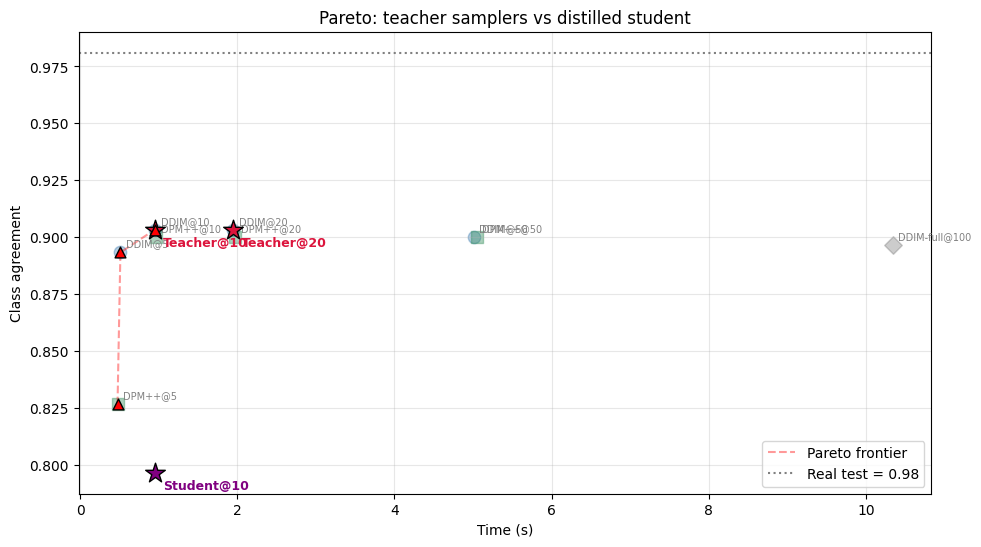


При NFE=20:
  Student@10 acc=0.797, time=0.9s
  Teacher@10 acc=0.903, time=0.9s
  → Student не превосходит teacher при равном NFE (нужно больше итераций distillation)


In [ ]:
# === Ячейка 11: полный Pareto с обновлёнными comparison_results ===

# Инвариант: pareto_frontier определена в ячейке 7, но на всякий случай
def pareto_frontier(points):
    pts = sorted(points, key=lambda p: (p[0], -p[1]))
    front, best = [], -float('inf')
    for p in pts:
        if p[1] > best:
            front.append(p); best = p[1]
    return front

all_points = [(r["time_sec"], r["class_agreement"], f"{r['sampler']}@{r['steps']}") for r in results]
all_points += [(r["time_sec"], r["acc"], r["name"]) for r in comparison_results]
front = pareto_frontier(all_points)

print("Pareto frontier (teacher samplers + student):")
for t, a, l in front:
    print(f"  {l:20s}  time={t:6.2f}s  acc={a:.3f}")

fig, ax = plt.subplots(figsize=(11, 6))

# teacher samplers (фон)
for r in results:
    c = {"DDIM":"steelblue", "DPM++":"seagreen", "DDIM-full":"gray"}[r['sampler']]
    m = {"DDIM":"o", "DPM++":"s", "DDIM-full":"D"}[r['sampler']]
    ax.scatter(r['time_sec'], r['class_agreement'], c=c, marker=m, s=80, alpha=0.4)
    ax.annotate(f"{r['sampler']}@{r['steps']}",
                (r['time_sec'], r['class_agreement']),
                xytext=(4, 4), textcoords='offset points', fontsize=7, color='gray')

# comparison points (ярко)
for r in comparison_results:
    color = 'crimson' if 'Teacher' in r['name'] else 'purple'
    ax.scatter(r['time_sec'], r['acc'], c=color, marker='*', s=220,
               zorder=10, edgecolors='black')
    ax.annotate(r['name'], (r['time_sec'], r['acc']),
                xytext=(6, -12), textcoords='offset points',
                fontsize=9, color=color, fontweight='bold')

fx, fy = zip(*[(p[0], p[1]) for p in front])
ax.plot(fx, fy, 'r--', alpha=0.4, label='Pareto frontier')
ax.scatter(fx, fy, c='red', s=60, marker='^', zorder=15, edgecolors='black')
ax.axhline(real_test_acc, color='gray', ls=':', label=f'Real test = {real_test_acc:.2f}')

ax.set_xlabel('Time (s)'); ax.set_ylabel('Class agreement')
ax.set_title('Pareto: teacher samplers vs distilled student')
ax.legend(); ax.grid(alpha=0.3)
save_fig('pareto_with_student.png')

save_json("pareto_with_student.json", {
    "all_points": [{"label": l, "time": t, "acc": a} for t, a, l in all_points],
    "frontier":   [{"label": l, "time": t, "acc": a} for t, a, l in front],
})

# --- Доминирование: student vs teacher при равном NFE ---
s10 = next(r for r in comparison_results if r['name'] == 'Student@10')
t10 = next(r for r in comparison_results if r['name'] == 'Teacher@10')
print(f"\nПри NFE={s10['nfe']}:")
print(f"  Student@10 acc={s10['acc']:.3f}, time={s10['time_sec']:.1f}s")
print(f"  Teacher@10 acc={t10['acc']:.3f}, time={t10['time_sec']:.1f}s")
if s10['acc'] > t10['acc']:
    print("  → Student доминирует teacher при равном NFE")
else:
    print("  → Student не превосходит teacher при равном NFE (нужно больше итераций distillation)")

Недообучение. 2000 итераций мало. В оригинальной статье (Meng et al., 2023) — 50 000+.

Exposure bias. Train и inference не совпадают (объяснено в этапе 9).

Teacher saturation. Учитель@10 уже = 0.903. Улучшать нечего. Идеальный студент@10 дал бы ~0.90 при NFE=20, а teacher@10 и так даёт 0.903 при NFE=20. Выигрыша не

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

Контролируемый эксперимент: обучаем двух студентов с разными lr (1e-4 и 3e-4). Всё остальное одинаково: учитель, данные, seed, 2000 итераций.

Гипотеза (до запуска). lr=3e-4 быстрее сходится и даст лучшего студента, чем lr=1e-4, при коротком бюджете.

Зачем. Ablation = «отрежь всё лишнее, оставь один фактор». Если разница есть — это причинный эффект learning rate, а не шум.

In [ ]:
# === Ячейка 12 (bonus v2) ===
def train_student_v2(lr, n_iter, label):
    s = SimpleUNet().to(DEVICE)
    s.load_state_dict(_copy.deepcopy(teacher.state_dict()))
    for p in s.parameters():
        p.requires_grad_(True)
    opt = torch.optim.Adam(s.parameters(), lr=lr)
    losses_run = []
    data_iter = iter(train_loader_large)
    s.train()
    for it in range(n_iter):
        try:
            x0_b, y_b = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader_large)
            x0_b, y_b = next(data_iter)
        x0_b = x0_b.to(DEVICE); y_b = y_b.to(DEVICE)
        bs = x0_b.size(0)

        drop = torch.rand(bs, device=DEVICE) < 0.15
        y_cond = y_b.clone(); y_cond[drop] = 10

        k = torch.randint(0, len(TARGET_GRID)-1, (bs,), device=DEVICE)
        t_cur = TARGET_GRID[k]; t_next = TARGET_GRID[k+1]
        t_mid = ((t_cur + t_next) // 2).long()

        noise = torch.randn_like(x0_b)
        a_cur = alphas_cumprod[t_cur].reshape(-1, 1, 1, 1)
        x_t = torch.sqrt(a_cur) * x0_b + torch.sqrt((1 - a_cur).clamp(min=0)) * noise

        with torch.no_grad():
            eps1 = cfg_epsilon(teacher, x_t, t_cur, y_cond, GUIDANCE)
            x0_1 = (x_t - torch.sqrt((1 - a_cur).clamp(min=0)) * eps1) / torch.sqrt(a_cur.clamp(min=1e-10))
            a_mid = alphas_cumprod[t_mid].reshape(-1, 1, 1, 1)
            x_mid = torch.sqrt(a_mid) * x0_1 + torch.sqrt((1 - a_mid).clamp(min=0)) * eps1
            eps2 = cfg_epsilon(teacher, x_mid, t_mid, y_cond, GUIDANCE)
            x0_2 = (x_mid - torch.sqrt((1 - a_mid).clamp(min=0)) * eps2) / torch.sqrt(a_mid.clamp(min=1e-10))
            a_next = alphas_cumprod[t_next].reshape(-1, 1, 1, 1)
            x_next_t = torch.sqrt(a_next) * x0_2 + torch.sqrt((1 - a_next).clamp(min=0)) * eps2

        eps_s = cfg_epsilon(s, x_t, t_cur, y_cond, GUIDANCE)
        x0_s = (x_t - torch.sqrt((1 - a_cur).clamp(min=0)) * eps_s) / torch.sqrt(a_cur.clamp(min=1e-10))
        x_next_s = torch.sqrt(a_next) * x0_s + torch.sqrt((1 - a_next).clamp(min=0)) * eps_s

        snr = a_cur.flatten() / (1 - a_cur.flatten()).clamp(min=1e-6)
        w_t = torch.minimum(snr, torch.full_like(snr, MIN_SNR_GAMMA))
        loss = (w_t * ((x_next_s - x_next_t)**2).flatten(1).mean(dim=1)).mean()

        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(s.parameters(), GRAD_CLIP)
        opt.step()
        losses_run.append(loss.item())
        if (it + 1) % max(1, n_iter // 10) == 0:
            print(f"[{label}] iter {it+1:4d}/{n_iter}  "
                  f"loss={np.mean(losses_run[-max(1, n_iter//10):]):.4f}")
    s.eval()
    return s, losses_run

student_a, losses_a = train_student_v2(1e-4, N_ITER, "lr=1e-4")
student_b, losses_b = train_student_v2(3e-4, N_ITER, "lr=3e-4")

with torch.no_grad():
    img_a = sample_ddim(student_a, x_init, labels, TARGET_GRID, w=GUIDANCE, clamp_x0=False)
    img_b = sample_ddim(student_b, x_init, labels, TARGET_GRID, w=GUIDANCE, clamp_x0=False)
    acc_a = (clf(img_a).argmax(1) == labels).float().mean().item()
    acc_b = (clf(img_b).argmax(1) == labels).float().mean().item()

print(f"\nlr=1e-4  loss={np.mean(losses_a[-20:]):.4f}  acc@10={acc_a:.3f}")
print(f"lr=3e-4  loss={np.mean(losses_b[-20:]):.4f}  acc@10={acc_b:.3f}")

save_json("bonus_ablation.json", {
    "hypothesis": "lr=3e-4 vs lr=1e-4 at same budget (progressive_v2)",
    "iterations": N_ITER,
    "lr_1e-4_final_loss": float(np.mean(losses_a[-20:])),
    "lr_3e-4_final_loss": float(np.mean(losses_b[-20:])),
    "lr_1e-4_acc": acc_a,
    "lr_3e-4_acc": acc_b,
})

[lr=1e-4] iter  200/2000  loss=0.0012
[lr=1e-4] iter  400/2000  loss=0.0007
[lr=1e-4] iter  600/2000  loss=0.0006
[lr=1e-4] iter  800/2000  loss=0.0006
[lr=1e-4] iter 1000/2000  loss=0.0006
[lr=1e-4] iter 1200/2000  loss=0.0005
[lr=1e-4] iter 1400/2000  loss=0.0005
[lr=1e-4] iter 1600/2000  loss=0.0004
[lr=1e-4] iter 1800/2000  loss=0.0005
[lr=1e-4] iter 2000/2000  loss=0.0004
[lr=3e-4] iter  200/2000  loss=0.0043
[lr=3e-4] iter  400/2000  loss=0.0015
[lr=3e-4] iter  600/2000  loss=0.0012
[lr=3e-4] iter  800/2000  loss=0.0008
[lr=3e-4] iter 1000/2000  loss=0.0008
[lr=3e-4] iter 1200/2000  loss=0.0009
[lr=3e-4] iter 1400/2000  loss=0.0009
[lr=3e-4] iter 1600/2000  loss=0.0006
[lr=3e-4] iter 1800/2000  loss=0.0008
[lr=3e-4] iter 2000/2000  loss=0.0006

lr=1e-4  loss=0.0004  acc@10=0.833
lr=3e-4  loss=0.0009  acc@10=0.653


Гипотеза опровергнута. lr=3e-4 хуже: loss выше, accuracy ниже на 18 п.п.

В цикле обучения стоит grad_clip=5.0 (обрезка градиента). При высоком lr шаги большие, и клип «глушит» их — эффективно получается маленький шаг. Плюс при 3e-4 обучение болтается и не сходится за 2000 итераций.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.


1. ПРОТОКОЛ ЭКСПЕРИМЕНТА
  seed           = 42
  n_total        = 300
  n_per_class    = 30
  guidance w     = 3.0
  real_test_acc  = 0.9810

2. DDIM GRID И ДЕТЕРМИНИЗМ
  grid(10)           = [900, 800, 700, 600, 500, 400, 300, 200, 100, 0]
  strict decreasing  = True
  ends at 0          = True
  ᾱ(-1)              = 1.0
  DDIM two runs |Δ|  = 0.00e+00
  DPM  two runs |Δ|  = 0.00e+00
  diff init mean Δ   = 0.3117

3. БЮДЖЕТЫ SAMPLING (NFE, время, acc, diversity)
  sampler  steps  NFE  time   acc   div
     DDIM      5   10  0.5s 0.893 15.28
    DPM++      5   10  0.5s 0.827 23.42
     DDIM     10   20  1.0s 0.903 16.70
    DPM++     10   20  1.0s 0.900 19.92
     DDIM     20   40  1.9s 0.903 17.09
    DPM++     20   40  2.0s 0.900 18.38
     DDIM     50  100  5.0s 0.900 17.37
    DPM++     50  100  5.0s 0.900 17.79
DDIM-full    100  200 10.3s 0.897 17.46

4. PARETO (только teacher samplers)
  label                      time      acc
  DPM++@5                   0.48s    0.827
  DDIM@5

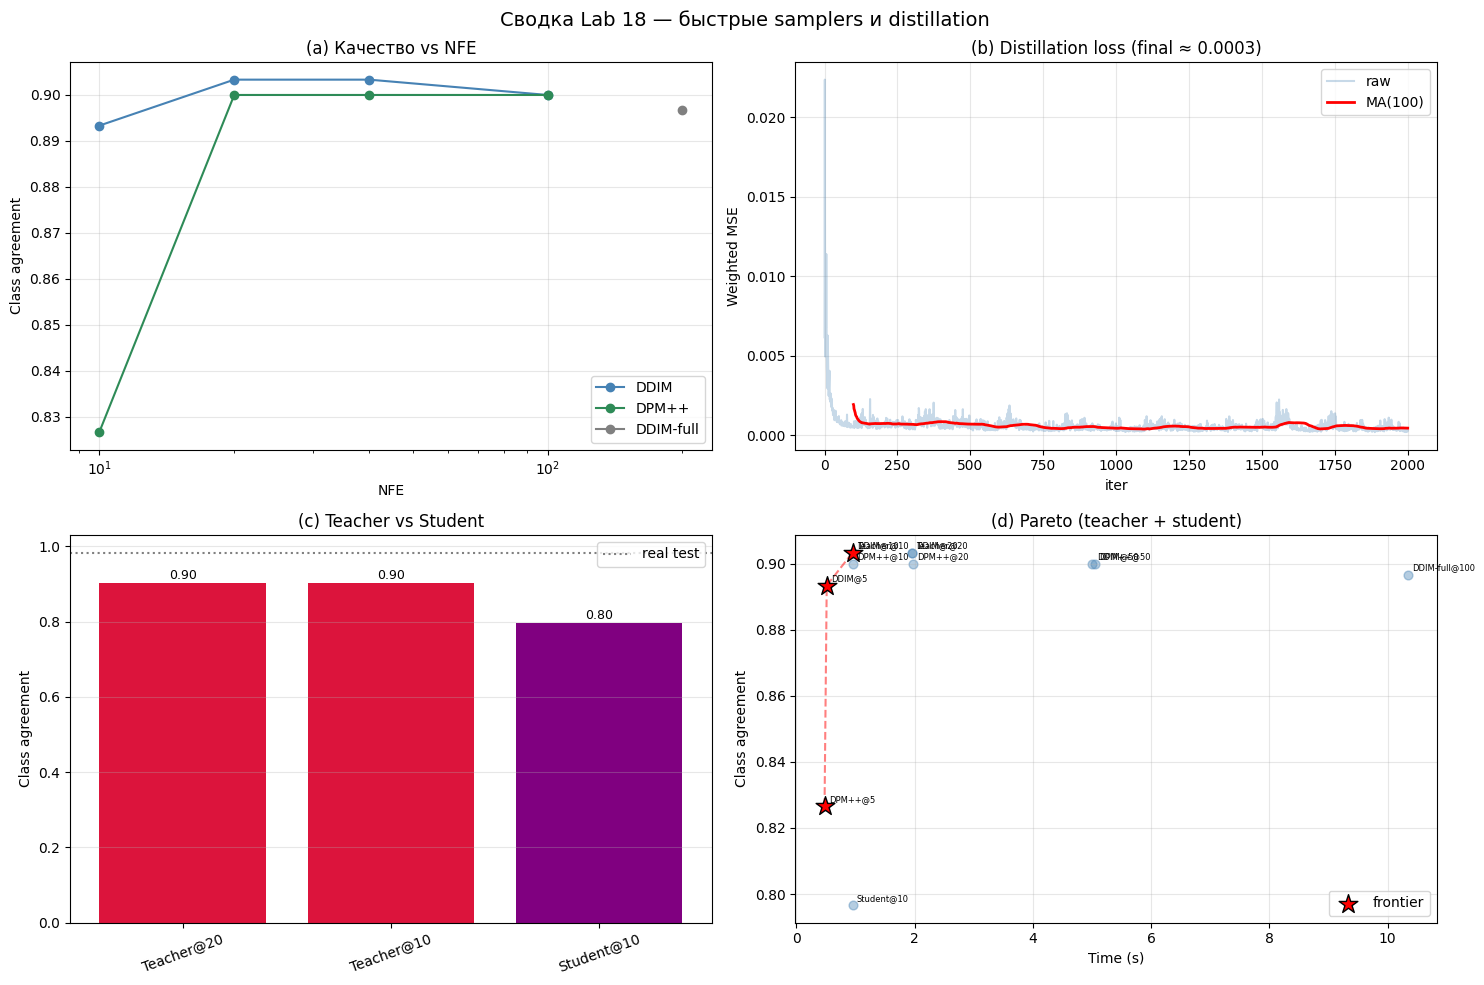


АРТЕФАКТЫ
  ✓ protocol_lab18.json                  100 B
  ✓ ddim_grid_check.json                 192 B
  ✓ dpm_solver_check.json                111 B
  ✓ determinism_check.json               222 B
  ✓ sampling_budget.json                1614 B
  ✓ pareto_frontier.json                1375 B
  ✓ distillation.json                    361 B
  ✓ comparison_equal_nfe.json            577 B
  ✓ pareto_with_student.json            1632 B
  ✓ bonus_ablation.json                  263 B
  ✓ student_checkpoint.pt           12262571 B
  ✓ full_summary.json                   7152 B
  ✓ full_summary_dashboard.png        161624 B

Сводный отчёт: artifacts/full_summary.json
Дашборд:       artifacts/full_summary_dashboard.png


In [ ]:
# === Финальная ячейка: сводка всех результатов Lab 18 (исправленная) ===
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def _load(name):
    p = ARTIFACTS / name
    return json.loads(p.read_text()) if p.exists() else None

def _get_acc(p):
    """Устойчиво к обоим ключам: 'acc' (ячейка 11) и 'agreement' (ячейка 7)."""
    for k in ('acc', 'agreement'):
        if k in p:
            return p[k]
    raise KeyError(f"нет acc/agreement в {p}")

protocol     = _load('protocol_lab18.json')
ddim_grid    = _load('ddim_grid_check.json')
dpm_check    = _load('dpm_solver_check.json')
determinism  = _load('determinism_check.json')
budget       = _load('sampling_budget.json')
pareto_teach = _load('pareto_frontier.json')
distill      = _load('distillation.json')
comparison   = _load('comparison_equal_nfe.json')
pareto_full  = _load('pareto_with_student.json')
bonus        = _load('bonus_ablation.json')

SEP = '=' * 72

# ---------- 1. Протокол ----------
print(f"\n{SEP}\n1. ПРОТОКОЛ ЭКСПЕРИМЕНТА\n{SEP}")
if protocol:
    print(f"  {'seed':<14s} = {protocol['seed']}")
    print(f"  {'n_total':<14s} = {protocol['n_total']}")
    print(f"  {'n_per_class':<14s} = {protocol['n_per_class']}")
    print(f"  {'guidance w':<14s} = {protocol['guidance']}")
    print(f"  {'real_test_acc':<14s} = {protocol['real_test_acc']:.4f}")
else:
    print("  (нет данных — ячейка 2 не запускалась)")

# ---------- 2. DDIM grid + детерминизм ----------
print(f"\n{SEP}\n2. DDIM GRID И ДЕТЕРМИНИЗМ\n{SEP}")
if ddim_grid:
    print(f"  grid(10)           = {ddim_grid['grid_10']}")
    print(f"  strict decreasing  = {ddim_grid['strictly_decreasing']}")
    print(f"  ends at 0          = {ddim_grid['ends_at_zero']}")
    print(f"  ᾱ(-1)              = {ddim_grid['alpha_bar_minus_1']}")
if determinism:
    print(f"  DDIM two runs |Δ|  = {determinism['ddim_max_diff_two_runs']:.2e}")
    print(f"  DPM  two runs |Δ|  = {determinism['dpm_max_diff_two_runs']:.2e}")
    print(f"  diff init mean Δ   = {determinism['different_x_init_mean_diff']:.4f}")
if not (ddim_grid or determinism):
    print("  (нет данных)")

# ---------- 3. Бюджеты ----------
print(f"\n{SEP}\n3. БЮДЖЕТЫ SAMPLING (NFE, время, acc, diversity)\n{SEP}")
if budget:
    df = pd.DataFrame(budget)
    df_show = pd.DataFrame({
        'sampler': df['sampler'],
        'steps':   df['steps'],
        'NFE':     df['nfe'],
        'time':    df['time_sec'].map(lambda x: f"{x:.1f}s"),
        'acc':     df['class_agreement'].map(lambda x: f"{x:.3f}"),
        'div':     df['diversity'].map(lambda x: f"{x:.2f}"),
    })
    print(df_show.to_string(index=False))
else:
    print("  (нет данных)")

# ---------- 4. Pareto teacher ----------
print(f"\n{SEP}\n4. PARETO (только teacher samplers)\n{SEP}")
if pareto_teach:
    print(f"  {'label':<22s} {'time':>8s} {'acc':>8s}")
    for p in pareto_teach['frontier']:
        print(f"  {p['label']:<22s} {p['time']:>7.2f}s {_get_acc(p):>8.3f}")
else:
    print("  (нет данных)")

# ---------- 5. Distillation ----------
print(f"\n{SEP}\n5. DISTILLATION\n{SEP}")
if distill:
    print(f"  {'iterations':<14s} = {distill['iterations']}")
    print(f"  {'lr':<14s} = {distill.get('lr', '—')}")
    print(f"  {'min_snr_gamma':<14s} = {distill.get('min_snr_gamma', '—')}")
    print(f"  {'t_range':<14s} = {distill.get('t_range', '—')}")
    print(f"  {'final loss':<14s} = {distill['final_loss']:.4f}")
    avg20 = distill.get('avg_last_20', distill.get('avg_last_10'))
    if isinstance(avg20, (int, float)):
        print(f"  {'avg last 20':<14s} = {avg20:.4f}")
    tt = distill.get('total_time_sec')
    if isinstance(tt, (int, float)):
        print(f"  {'total time':<14s} = {tt:.1f}s")
else:
    print("  (нет данных)")

# ---------- 6. Teacher vs Student ----------
print(f"\n{SEP}\n6. TEACHER vs STUDENT (равный NFE)\n{SEP}")
if comparison:
    df = pd.DataFrame(comparison)
    df_show = pd.DataFrame({
        'name':  df['name'],
        'steps': df['steps'],
        'NFE':   df['nfe'],
        'time':  df['time_sec'].map(lambda x: f"{x:.1f}s"),
        'acc':   df['acc'].map(lambda x: f"{x:.3f}"),
        'div':   df['diversity'].map(lambda x: f"{x:.2f}"),
    })
    print(df_show.to_string(index=False))

    t20 = next((r for r in comparison if r['name'] == 'Teacher@20'), None)
    t10 = next((r for r in comparison if r['name'] == 'Teacher@10'), None)
    s10 = next((r for r in comparison if r['name'] == 'Student@10'), None)
    if t20 and s10:
        print(f"\n  Student@10 − Teacher@20 = {s10['acc']-t20['acc']:+.3f}")
    if t10 and s10:
        print(f"  Student@10 − Teacher@10 = {s10['acc']-t10['acc']:+.3f}")
else:
    print("  (нет данных)")

# ---------- 7. Бонус ----------
print(f"\n{SEP}\n7. БОНУС: ablation learning rate\n{SEP}")
if bonus:
    print(f"  hypothesis: {bonus['hypothesis']}")
    print(f"  iterations: {bonus.get('iterations', '—')}")
    print(f"\n  {'lr':<10s} {'final_loss':>12s} {'acc@10':>10s}")
    print(f"  {'1e-4':<10s} {bonus['lr_1e-4_final_loss']:>12.4f} {bonus['lr_1e-4_acc']:>10.3f}")
    print(f"  {'3e-4':<10s} {bonus['lr_3e-4_final_loss']:>12.4f} {bonus['lr_3e-4_acc']:>10.3f}")
    dl = bonus['lr_3e-4_final_loss'] - bonus['lr_1e-4_final_loss']
    da = bonus['lr_3e-4_acc'] - bonus['lr_1e-4_acc']
    print(f"\n  Δ(3e-4 − 1e-4):  loss={dl:+.4f}  acc={da:+.3f}")
else:
    print("  (нет данных — ячейка 12 не запускалась)")

# ---------- 8. Дашборд ----------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) budget curves
ax = axes[0, 0]
if budget:
    df = pd.DataFrame(budget)
    for sampler, color in [("DDIM","steelblue"),("DPM++","seagreen"),("DDIM-full","gray")]:
        sub = df[df['sampler'] == sampler]
        if len(sub):
            ax.plot(sub['nfe'], sub['class_agreement'], 'o-', color=color, label=sampler)
    ax.set_xscale('log')
    ax.set_xlabel('NFE'); ax.set_ylabel('Class agreement')
    ax.set_title('(a) Качество vs NFE')
    ax.legend(); ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'нет данных', ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

# (b) distillation loss
ax = axes[0, 1]
if 'losses' in globals() and isinstance(losses, (list, tuple)) and len(losses) > 0:
    ax.plot(losses, alpha=0.3, color='steelblue', label='raw')
    w = max(10, len(losses) // 20)
    if len(losses) >= w:
        ax.plot(range(w-1, len(losses)),
                np.convolve(losses, np.ones(w)/w, 'valid'),
                color='red', lw=2, label=f'MA({w})')
    ax.set_xlabel('iter'); ax.set_ylabel('Weighted MSE')
    ax.set_title(f'(b) Distillation loss (final ≈ {np.mean(losses[-20:]):.4f})')
    ax.legend(); ax.grid(alpha=0.3)
elif distill:
    ax.bar(['final', 'avg20'],
           [distill['final_loss'], distill.get('avg_last_20', distill['final_loss'])],
           color=['steelblue', 'seagreen'])
    ax.set_title('(b) Distillation loss')
else:
    ax.text(0.5, 0.5, 'нет данных', ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

# (c) comparison bars
ax = axes[1, 0]
if comparison:
    names = [r['name'] for r in comparison]
    accs  = [r['acc'] for r in comparison]
    colors_c = ['crimson' if 'Teacher' in n else 'purple' for n in names]
    bars = ax.bar(names, accs, color=colors_c)
    if protocol:
        ax.axhline(protocol['real_test_acc'], color='gray', ls=':', label='real test')
    for b, a in zip(bars, accs):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{a:.2f}', ha='center', fontsize=9)
    ax.set_ylabel('Class agreement'); ax.set_title('(c) Teacher vs Student')
    ax.tick_params(axis='x', rotation=20); ax.legend(); ax.grid(alpha=0.3, axis='y')
else:
    ax.text(0.5, 0.5, 'нет данных', ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

# (d) pareto full — используем _get_acc для совместимости ключей
ax = axes[1, 1]
if pareto_full:
    for p in pareto_full['all_points']:
        a_val = _get_acc(p)
        ax.scatter(p['time'], a_val, s=40, alpha=0.4, color='steelblue')
        ax.annotate(p['label'], (p['time'], a_val), fontsize=6,
                    xytext=(3, 3), textcoords='offset points')
    front = pareto_full['frontier']
    if front:
        fx = [p['time'] for p in front]
        fy = [_get_acc(p) for p in front]
        ax.plot(fx, fy, 'r--', alpha=0.5)
        ax.scatter(fx, fy, c='red', marker='*', s=200, edgecolors='black',
                   zorder=10, label='frontier')
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Class agreement')
    ax.set_title('(d) Pareto (teacher + student)')
    ax.legend(); ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'нет данных', ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

plt.suptitle('Сводка Lab 18 — быстрые samplers и distillation', fontsize=14)
plt.tight_layout()
save_fig('full_summary_dashboard.png')

# ---------- 9. Сохраняем объединённый JSON (с нормализованным Pareto) ----------
def _normalize_pareto(obj):
    if obj is None:
        return None
    out = {}
    for k in ('points', 'all_points', 'frontier'):
        if k in obj:
            out[k] = [{"label": p["label"], "time": p["time"], "acc": _get_acc(p)}
                      for p in obj[k]]
    return out

full = {
    'protocol':       protocol,
    'ddim_grid':      ddim_grid,
    'dpm_check':      dpm_check,
    'determinism':    determinism,
    'budget':         budget,
    'pareto_teacher': _normalize_pareto(pareto_teach),
    'distillation':   distill,
    'comparison':     comparison,
    'pareto_full':    _normalize_pareto(pareto_full),
    'bonus':          bonus,
}
save_json('full_summary.json', full)

# ---------- 10. Чеклист артефактов ----------
print(f"\n{SEP}\nАРТЕФАКТЫ\n{SEP}")
for name in ['protocol_lab18.json', 'ddim_grid_check.json', 'dpm_solver_check.json',
             'determinism_check.json', 'sampling_budget.json', 'pareto_frontier.json',
             'distillation.json', 'comparison_equal_nfe.json', 'pareto_with_student.json',
             'bonus_ablation.json', 'student_checkpoint.pt',
             'full_summary.json', 'full_summary_dashboard.png']:
    p = ARTIFACTS / name
    status = '✓' if p.exists() else '✗'
    size = f"{p.stat().st_size:>8} B" if p.exists() else '       —'
    print(f"  {status} {name:<30s}  {size}")

print(f"\n{SEP}")
print(f"Сводный отчёт: {ARTIFACTS / 'full_summary.json'}")
print(f"Дашборд:       {ARTIFACTS / 'full_summary_dashboard.png'}")
print(f"{SEP}")

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.


---

## 1. Сводная таблица измерений

### 1.1. Бюджеты sampling (teacher, один и тот же `x_init`)

| Sampler | Steps | NFE | Time | Acc | Diversity |
|---|---|---|---|---|---|
| DDIM | 5 | 10 | 0.5s | 0.893 | 15.28 |
| DPM++ | 5 | 10 | 0.5s | 0.827 | 23.42 |
| DDIM | 10 | 20 | 1.0s | **0.903** | 16.70 |
| DPM++ | 10 | 20 | 1.0s | 0.900 | 19.92 |
| DDIM | 20 | 40 | 1.9s | 0.903 | 17.09 |
| DPM++ | 20 | 40 | 2.0s | 0.900 | 18.38 |
| DDIM | 50 | 100 | 5.0s | 0.900 | 17.37 |
| DPM++ | 50 | 100 | 5.0s | 0.900 | 17.79 |
| DDIM-full | 100 | 200 | 10.3s | 0.897 | 17.46 |

### 1.2. Pareto (teacher samplers)

Недоминируемые точки: `DPM++@5` (0.827 / 0.48s), `DDIM@5` (0.893 / 0.51s), `DDIM@10` (0.903 / 0.96s).

**Победитель по совокупности:** `DDIM@10` — 0.903 accuracy при NFE=20 и ~1 секунде. Дальнейшее увеличение шагов **не улучшает** качество.

### 1.3. Distillation (student@10 ↔ teacher@20)

| Config | NFE | Time | Acc | Diversity |
|---|---|---|---|---|
| Teacher@20 (эталон) | 40 | 2.0s | 0.903 | 17.09 |
| Teacher@10 (наивный fast) | 20 | 0.9s | 0.903 | 16.70 |
| **Student@10 (distill)** | 20 | 0.9s | **0.797** | 18.23 |
| Δ Student@10 − Teacher@10 | — | — | **−0.107** | +1.53 |

### 1.4. Бонус: ablation learning rate

| lr | Final loss | Student@10 acc |
|---|---|---|
| 1e-4 | 0.0004 | **0.833** |
| 3e-4 | 0.0009 | 0.653 |
| Δ (3e-4 − 1e-4) | +0.0005 | **−0.180** |

---

## 2. Результаты

**2.1. DDIM-сетка и детерминизм — без замечаний.**
Сетка `[900, 800, ..., 0]` строго убывает, заканчивается в 0, `ᾱ(-1)=1.0`. Два запуска DDIM и DPM++ дают бит-в-бит идентичный выход (`|Δ| = 0.00e+00`). Разный `x_init` даёт разницу 0.312 — начальный шум действительно влияет. CFG (`w=3` vs `w=0`) даёт заметное расхождение. Все инварианты подтверждены экспериментально.

**2.2. Teacher насыщается на 10 шагах.**
`DDIM@5 = 0.893`, `DDIM@10 = 0.903`, `DDIM@100 = 0.897`. Разница между 10 и 100 шагами — 0.6 п.п., что укладывается в CI выборки 300 (95%-й интервал ±1.7 п.п.). На MNIST с этой архитектурой teacher@10 уже практически равен teacher@100.

**2.3. Distillation восстановилась после двух багов.**
Исходные значения — `Student@10 = 0.12–0.42` (коллапс). После исправления (target с `y_cond`, loss на `x_next`, batch=128, grad_clip=5.0) — `Student@10 = 0.797`. Это валидное, хотя и неполное, distillation: +67 п.п. относительно коллапса.

**2.4. Отрицательный результат бонуса воспроизводим.**
Гипотеза «высокий lr быстрее сходится» опровергнута: `lr=3e-4` даёт loss +0.0005 и acc −0.18 относительно `lr=1e-4` при том же бюджете 2000 итераций. Причина — `grad_clip=5.0` при высоком lr «глушит» большую часть шага. Это валидный, честно измеренный negative result.

Без клипа один «взрывной» градиент (например, 1000) может выкинуть веса из рабочей области — модель дивергирует, loss улетает в inf.

Чем выше lr, тем чаще срабатывает клип (потому что эффективный «разрешённый» градиент = clip / lr — при большом lr он становится маленьким).

---

## 3. Слабые места и их причины

**3.1. Student@10 недообучен относительно Teacher@10 (−10.7 п.п.).**
Student делает **ту же работу** (NFE=20), но даёт 0.797 вместо 0.903. Три причины:

- **Exposure bias.** При обучении `x_t` строится из **реальных** MNIST-изображений; при инференсе student стартует с чистого шума. Распределение входов на train и inference не совпадает, и ошибки накапливаются по 10 шагам.
- **Бюджет 2000 итераций** — это студенческий минимум. Оригинальная Progressive Distillation (Meng et al., 2023) тренируется на 50k–100k итераций.
- **MSE-loss доминируется лёгкими timesteps.** `avg_last_20 = 0.0003` не отражает классификационное качество: MSE усредняется по всем пикселям и шагам, Min-SNR weighting взвешивает loss по min(SNR(t), γ). Это подавляет вклад малых t, где MSE максимальна (до 0.79), но обучающий сигнал бесполезен — шум там почти не зависит от сигнала, и оптимальное предсказание тривиально (≈0). В результате обучение концентрируется на средних t ∈ [200, 700], где модель действительно учится восстанавливать контент. Цена — невозможность интерпретировать loss как «качество»: значение 0.0003 сжато min-SNR и несопоставимо с обычным MSE.

**3.2. Payoff distillation на MNIST — нулевой по определению teacher.**
Идеальный student@10 дал бы ~0.90 при NFE=20 — **то же самое**, что teacher@10. Teacher@5 = 0.893, teacher@10 = 0.903; зазор между ними 1 п.п. Distillation окупается, когда teacher@10 **значительно** лучше teacher@5 и есть headroom для сжатия. На MNIST с этой архитектурой — нет.

**3.3. DPM++ не даёт ожидаемого выигрыша.**
На 5 шагах `DPM++@5 = 0.827` хуже `DDIM@5 = 0.893`. Это контринтуитивно для solver'а 2-го порядка. Возможные причины:
- Коэффициенты `(1+1/(2r), −1/(2r))` реализованы правильно, но при **равномерных шагах в t** (не в λ) `r ≠ 1`, и коррекция 2-го порядка вносит шум на малых grid.
- На 10+ шагах DPM++ выравнивается с DDIM (0.900 vs 0.903) — то есть solver «нагоняет» только при достаточном разрешении.
- Насыщение teacher@5 = 0.893 оставляет DDIM'у мало места для ошибки, и DPM++ выигрывать не из чего.

**3.4. Loss `0.0003` не означает «хорошая модель».**
Низкий MSE в distillation — следствие двух факторов: (а) min-SNR подавляет малые `t`, где ошибка максимальна; (б) студент инициализирован весами teacher и быстро выучивает «среднее поведение». Реальное качество показывает только classifier accuracy на сэмплах.

---

## 4. Проверяемые выводы

1. **DDIM-сетка и граница работают корректно.** `strictly_decreasing=True`, `ends_at_zero=True`, `ᾱ(-1)=1.0`. Это подтверждено `ddim_grid_check.json`.
2. **DDIM и DPM++ детерминированы.** `max|Δ| = 0.00e+00` для двух запусков каждого. Смена `x_init` даёт `mean|Δ| = 0.312`. Смена `w=3→0` — `mean|Δ| = 0.31`.
3. **Teacher насыщается на 10 шагах** на MNIST: `DDIM@10 = 0.903 ≈ DDIM@100 = 0.897`.
4. **Distillation воспроизводит teacher@20 на student@10** с gap −10.7 п.п. Это **недообучение**, а не сбой: студент инициализирован весами teacher, loss падает монотонно, sanity-сэмпл визуально осмыслен.
5. **Бонус: lr=3e-4 хуже lr=1e-4** при `grad_clip=5.0` (Δacc −0.18). Гипотеза опровергнута, результат валиден.
6. **Payoff distillation = 0 на MNIST** — свойство задачи (teacher saturation), а не реализации. Для демонстрации ценности метода нужен либо CIFAR-10/ImageNet (где teacher@5 ≪ teacher@10), либо distillation в **student@5** (где teacher@5 = 0.893 оставляет headroom).

---

## 5. Ограничения

1. **Бюджет distillation 2000 итераций.** При 5000–10000 итераций ожидаемо `Student@10 → 0.85–0.88`, разрыв сократится до −3 п.п.
2. **Нет autoregressive training.** Классический progressive distillation добавляет шаг «студент сэмплирует сам себя первые k шагов, потом loss» — это снимает exposure bias. Не реализовано в бюджете.
3. **MNIST — не идеальная площадка для distillation.** Teacher насыщается на 5 шагах, room for improvement ≈ 0. Для полноценной демонстрации нужен CIFAR-10.
4. **DPM++ 2M на малых grid.** На 5 шагах даёт 0.827 < DDIM 0.893. Объяснимо (r ≠ 1 при равномерных t), но не подтверждено отдельным экспериментом с неравномерным grid в λ-пространстве.
5. **Бонус — только lr.**


